<a href="https://colab.research.google.com/github/mohany606/Linear-Models-and-Support-Vector-Machines-from-Scratch/blob/main/ML_Assigmment_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Part A: Data:**

In [ ]:
from sklearn.model_selection import train_test_split
import numpy as np
from sklearn.datasets import (
    load_diabetes,
    load_breast_cancer,
    load_digits,
    load_iris
)
# 1. Diabetes
diabetes = load_diabetes(scaled=False)
X_diabetes = diabetes.data
y_diabetes = diabetes.target
# 2. Breast Cancer
cancer = load_breast_cancer()
X_cancer = cancer.data
y_cancer = 1 - cancer.target  # Malignant = 1
# 3. Digits
digits = load_digits()
X_digits = digits.data / 16.0
y_digits = digits.target
# 4. Iris
iris = load_iris()
X_iris = iris.data
y_iris = iris.target
def split_data(X, y, regression=False):
    stratify = None if regression else y
    # First split
    X_temp, X_test, y_temp, y_test = train_test_split(
        X, y,
        test_size=0.2,
        random_state=42,
        stratify=stratify
    )
    # Second split
    stratify_temp = None if regression else y_temp

    X_train, X_val, y_train, y_val = train_test_split(
        X_temp, y_temp,
        test_size=0.25,
        random_state=42,
        stratify=stratify_temp
    )

    return X_train, X_val, X_test, y_train, y_val, y_test


In [ ]:

datasets = {
    "Diabetes": (X_diabetes, y_diabetes, True),
    "Breast Cancer": (X_cancer, y_cancer, False),
    "Digits": (X_digits, y_digits, False),
    "Iris": (X_iris, y_iris, False)
}

splits = {}

for name, (X, y, regression) in datasets.items():
    splits[name] = split_data(X, y, regression)

    X_train, X_val, X_test, y_train, y_val, y_test = splits[name]
    print(f"\n{name}")
    print("Train:", X_train.shape)
    print("Validation:", X_val.shape)
    print("Test:", X_test.shape)

    if not regression:
        print("Train class counts:", np.bincount(y_train))
        print("Validation class counts:", np.bincount(y_val))
        print("Test class counts:", np.bincount(y_test))



Diabetes
Train: (264, 10)
Validation: (89, 10)
Test: (89, 10)

Breast Cancer
Train: (341, 30)
Validation: (114, 30)
Test: (114, 30)
Train class counts: [214 127]
Validation class counts: [71 43]
Test class counts: [72 42]

Digits
Train: (1077, 64)
Validation: (360, 64)
Test: (360, 64)
Train class counts: [106 109 107 109 109 109 109 107 104 108]
Validation class counts: [36 37 35 37 36 36 36 36 35 36]
Test class counts: [36 36 35 37 36 37 36 36 35 36]

Iris
Train: (90, 4)
Validation: (30, 4)
Test: (30, 4)
Train class counts: [30 30 30]
Validation class counts: [10 10 10]
Test class counts: [10 10 10]


In [ ]:


class Standardizer:
    def fit(self, X):
        self.mean = np.mean(X, axis=0)

        #each column feature
        self.std = np.std(X, axis=0)
        self.std[self.std == 0] = 1
        return self
    def transform(self, X):
        return (X - self.mean) / self.std

scaler = Standardizer()
#Why not call fit() separately for validation and testing?
#Because that would mean using different means and standard deviations for different sets.
#We want all three sets to use the same transformation.

def add_bias(X):
    return np.c_[np.ones(X.shape[0]), X]


processed_data = {}
scalers = {}
for name in datasets:

    X_train, X_val, X_test, y_train, y_val, y_test = splits[name]

    if name == "Digits":
        # Digits are already divided by 16.
        # NO standardize them.
        X_train_processed = X_train
        X_val_processed = X_val
        X_test_processed = X_test

    else:
        # Fit using training data only
        scaler = Standardizer()
        scaler.fit(X_train)

        X_train_processed = scaler.transform(X_train)
        X_val_processed = scaler.transform(X_val)
        X_test_processed = scaler.transform(X_test)

        scalers[name] = scaler

        train_mean = np.mean(X_train_processed, axis=0)
        train_std = np.std(X_train_processed, axis=0)

        print(f"\n{name} Standardizer verification:")
        print("Maximum absolute training mean:",
              np.max(np.abs(train_mean)))
        print("Training standard deviations:", train_std)

    X_train_final = add_bias(X_train_processed)
    X_val_final = add_bias(X_val_processed)
    X_test_final = add_bias(X_test_processed)

    processed_data[name] = (
        X_train_final,
        X_val_final,
        X_test_final,
        y_train,
        y_val,
        y_test
    )

print("\nAll datasets preprocessed successfully.")





Diabetes Standardizer verification:
Maximum absolute training mean: 2.2372676102294822e-15
Training standard deviations: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]

Breast Cancer Standardizer verification:
Maximum absolute training mean: 5.108979384873301e-15
Training standard deviations: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1.]

Iris Standardizer verification:
Maximum absolute training mean: 1.2927930331190711e-15
Training standard deviations: [1. 1. 1. 1.]

All datasets preprocessed successfully.


In [ ]:

#mean squared error
def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)
#Root Mean Squared Error
def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))
#R² — Coefficient of Determination
def r2(y_true, y_pred):
    s = np.sum((y_true - y_pred) ** 2)
    sm = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - (s / sm)
#Accuracy
def accuracy(y_true, y_pred):
    return np.mean(y_true == y_pred)
#Confusion Matrix
def confusion_matrix(y_true, y_pred, m):#m:number  of classes
    cm = np.zeros((m, m), dtype=int)
    np.add.at(cm, (y_true, y_pred), 1)#y_true, y_pred:m[i,j]
    return cm

def classification_metrics(cm):
    K = cm.shape[0]
    # True positives: diagonal
    TP = np.diag(cm)

    # Total predicted (column sums) TP+FP
    predicted = np.sum(cm, axis=0)

    # Total actual (row sums)TP+Fn
    actual = np.sum(cm, axis=1)

    # Precision
    # If a class is never predicted, precision = 0
    precision = np.divide(
        TP,
        predicted,
        out=np.zeros(K, dtype=float),
        where=predicted != 0
    )

    # Recall
    recall = np.divide(
        TP,
        actual,
        out=np.zeros(K, dtype=float),
        where=actual != 0
    )

    # F1-score
    f1 = np.divide(
        2 * precision * recall,
        precision + recall,
        out=np.zeros(K, dtype=float),
        where=(precision + recall) != 0
    )

    # Macro averages
    macro_precision = np.mean(precision)
    macro_recall = np.mean(recall)
    macro_f1 = np.mean(f1)

    return {
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "macro_precision": macro_precision,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1
    }



In [ ]:

from sklearn.metrics import (
    mean_squared_error,
    r2_score,
    accuracy_score,
    confusion_matrix as sk_confusion_matrix,
    precision_recall_fscore_support
)

rng = np.random.default_rng(42)

# Generate random classification labels
K = 4
N = 500

y_true = rng.integers(0, K, size=N)
y_pred = rng.integers(0, K, size=N)


cm = confusion_matrix(y_true, y_pred, K)
cm_sk = sk_confusion_matrix(
    y_true, y_pred,
    labels=np.arange(K) #[0, 1, 2, 3]
)

assert np.array_equal(cm, cm_sk) #If yes, the code continues.
#If no, Python raises an AssertionError and stops.


acc = accuracy(y_true, y_pred)
acc_sk = accuracy_score(y_true, y_pred)

assert abs(acc - acc_sk) < 1e-12 #tolerance error


our_metrics = classification_metrics(cm)

# sklearn metrics
p_sk, r_sk, f1_sk, _ = precision_recall_fscore_support(
    y_true,
    y_pred,
    labels=np.arange(K),
    average=None,
    zero_division=0
)
#np.allclose() compares two arrays element by element
assert np.allclose(our_metrics["precision"], p_sk, atol=1e-12)

assert np.allclose(our_metrics["recall"], r_sk, atol=1e-12)

assert np.allclose(our_metrics["f1"], f1_sk, atol=1e-12)

assert abs(our_metrics["macro_precision"] - np.mean(p_sk)) < 1e-12

assert abs( our_metrics["macro_recall"] - np.mean(r_sk)) < 1e-12

assert abs( our_metrics["macro_f1"] - np.mean(f1_sk)) < 1e-12

print("All classification metrics ")

# Generate random regression values
y_true_reg = rng.normal(size=500)
y_pred_reg = rng.normal(size=500)

# MSE
our_mse = mse(y_true_reg, y_pred_reg)
sk_mse = mean_squared_error(y_true_reg, y_pred_reg)

# RMSE
our_rmse = rmse(y_true_reg, y_pred_reg)
sk_rmse = np.sqrt(sk_mse)

# R2
our_r2 = r2(y_true_reg, y_pred_reg)
sk_r2 = r2_score(y_true_reg, y_pred_reg)

assert abs(our_mse - sk_mse) < 1e-12
assert abs(our_rmse - sk_rmse) < 1e-12
assert abs(our_r2 - sk_r2) < 1e-12

print("All regression metrics")



All classification metrics 
All regression metrics


In [ ]:

def grad_check(f, grad, w, eps=1e-5, num_checks=None):

    # Calculate analytical gradient
    g_analytic = grad(w)

    #with the same shape as w, but filled with zeros.
    g_numeric = np.zeros_like(w, dtype=float)

    # It converts an array into a one-dimensional array.
    w_flat = w.reshape(-1)
    g_flat = g_numeric.reshape(-1)
    #If the user doesn't specify how many weights to check,
    #or requests at least as many checks as there are weights, check all weights.
    if num_checks is None or num_checks >= w.size:
        indices = np.arange(w.size)
    else:
        rng = np.random.default_rng(42)
        indices = rng.choice(
            w.size,
            size=num_checks,
            replace=False
        )

    #numerical gradient
    for i in indices:
        w_plus = w.copy()
        w_minus = w.copy()
        w_plus.flat[i] += eps
        w_minus.flat[i] -= eps
        g_flat[i] = (f(w_plus) - f(w_minus) ) / (2 * eps)

    # Compare only the selected entries
    analytic_selected = g_analytic.flat[indices]
    numeric_selected = g_numeric.flat[indices]

    # np.linalg.norm() calculates the Euclidean length of this difference
    numerator = np.linalg.norm(
        analytic_selected - numeric_selected
    )

    denominator = max(
        np.linalg.norm(analytic_selected),
        np.linalg.norm(numeric_selected),
        1e-12
    )

    relative_error = numerator / denominator

    return relative_error


# **Part B :Linear Regression:**

# **5 Closed form**


Our model is:
$$\hat{y} = Xw$$

The cost function is:
$$J(w) = \frac{1}{2N}(Xw - y)^T(Xw - y)$$

Taking the gradient:
$$\nabla J(w) = \frac{1}{N}X^T(Xw - y)$$

At the minimum:
$$X^T(Xw - y) = 0$$

Rearranging:
$$X^TXw = X^Ty$$

And finally:
$$\boxed{w^* = (X^TX)^{-1}X^Ty}$$

In [ ]:

import pandas as pd
from sklearn.linear_model import LinearRegression

#getting the processed data for the Diabetes dataset
X_train_final, X_val_final, X_test_final, y_train, y_val, y_test = processed_data["Diabetes"]
#5 closed form solution
def normal_equation(X, y):
    A = X.T @ X
    b = X.T @ y
    w = np.linalg.solve(A, b) #solve sys of linear equations
    return w

# calculated the opt weights
w_normal = normal_equation(X_train_final, y_train)
print("Normal Equation Weights:")
print(w_normal)
#get el predictions
y_train_pred = X_train_final @ w_normal
y_val_pred = X_val_final @ w_normal
y_test_pred = X_test_final @ w_normal
print("Train RMSE:", rmse(y_train, y_train_pred))
print("Validation RMSE:", rmse(y_val, y_val_pred))
print("Test RMSE:", rmse(y_test, y_test_pred))
print("Test R2:", r2(y_test, y_test_pred))

feature_names = ["Bias"] + list(diabetes.feature_names)
weights_table = pd.DataFrame({"Feature": feature_names, "Weight": w_normal})
print(weights_table)

condition_number = np.linalg.cond(X_train_final.T @ X_train_final)
print("Condition Number:", condition_number)


Normal Equation Weights:
[149.81060606   1.13183676 -11.35931074  25.07661841  15.16733792
 -51.10135943  27.48082318  10.84029393  15.03214846  37.27158761
   3.81711191]
Train RMSE: 54.6103635732402
Validation RMSE: 51.1937139785339
Test RMSE: 54.15641293326043
Test R2: 0.4464263764021127
   Feature      Weight
0     Bias  149.810606
1      age    1.131837
2      sex  -11.359311
3      bmi   25.076618
4       bp   15.167338
5       s1  -51.101359
6       s2   27.480823
7       s3   10.840294
8       s4   15.032148
9       s5   37.271588
10      s6    3.817112
Condition Number: 505.7061226960868


# checking againist tiny data set

In [ ]:
#tiny dataset
X_example = np.array([
    [1, 1],
    [1, 2],
    [1, 3]
])

y_example = np.array([2, 3, 5])

N_example = X_example.shape[0]

In [ ]:
w_normal_example = normal_equation(X_example, y_example)

print("Normal Equation weights:", w_normal_example)

expected = np.array([1/3, 3/2]) #calculated by hand

print("Passed:", np.allclose(w_normal_example, expected))#why use np.allclose because it aprox compare 2 array == will result in rounding so wont be usf

Normal Equation weights: [0.33333333 1.5       ]
Passed: True


In [ ]:

#verify the results using sklearn LinearRegression
model = LinearRegression()

model.fit(X_train_final[:, 1:], y_train)

sklearn_weights = np.concatenate((
    [model.intercept_],
    model.coef_
))

print("my weights:")
print(w_normal)

print("Sklearn weights:")
print(sklearn_weights)

print("Maximum absolute difference:",
      np.max(np.abs(w_normal - sklearn_weights)))

assert np.allclose(w_normal, sklearn_weights, atol=1e-6)

my weights:
[149.81060606   1.13183676 -11.35931074  25.07661841  15.16733792
 -51.10135943  27.48082318  10.84029393  15.03214846  37.27158761
   3.81711191]
Sklearn weights:
[149.81060606   1.13183676 -11.35931074  25.07661841  15.16733792
 -51.10135943  27.48082318  10.84029393  15.03214846  37.27158761
   3.81711191]
Maximum absolute difference: 1.1510792319313623e-12


 Interpretation of Selected Coefficients

BMI (+25.08):The positive value means that when BMI increases, the predicted target value also tends to increase, assuming the other features stay the same

s1 (-51.10):The negative value means that when s1 increases, the predicted target value tends to decrease, while keeping the other features constant

s2 (+27.48):The positive value means that when s2 increases, the predicted target value also tends to increase, assuming the other features stay the same

Although s1 and s2 are related features, they have different coefficient signs. This is because the model considers all features together when calculating the weights. So, the effect of one feature can be influenced by the other features

These results show relationships between the features and the target, but they do not mean that one feature directly causes the target to increase or decrease

#**6 Gradient descent**

We'll start with:
$$w_0 = 0$$

Then repeatedly update the weights using:
$$w_{t+1} = w_t - \eta \nabla J(w_t)$$

We'll experiment with five learning rates:
$$\eta \in \{0.001,\ 0.01,\ 0.1,\ 0.5,\ 1.0\}$$

In [ ]:



def batch_gradient_descent(X, y, learning_rate, epochs):
    N = X.shape[0]
    # intialize weights to zeros
    w = np.zeros(X.shape[1])
    losses = []
    distances = []
    for epoch in range(epochs):
        # Calculate y^
        y_pred = X @ w
        #gradient
        gradient = (X.T @ (y_pred - y)) / N
        # Update w
        w = w - learning_rate * gradient
        # Calc loss
        y_pred = X @ w
        loss = np.sum((y_pred - y) ** 2) / (2 * N)
        losses.append(loss)
        # Compare current weights with Normal Equation weights
        distance = np.linalg.norm(w - w_normal) / np.linalg.norm(w_normal)
        distances.append(distance)
    return w, losses, distances
learning_rates = [0.001, 0.01, 0.1, 0.5, 1.0]
gd_results = {}

for n in learning_rates:
    w, losses, distances = batch_gradient_descent(X_train_final,y_train,n,epochs=2000)
    gd_results[n] = {"weights": w,"losses": losses,"distances": distances}
    print(f"\nLearning rate: {n}")
    print("Final loss:", losses[-1])
    print("Final relative distance:", distances[-1])


Learning rate: 0.001
Final loss: 1723.4028887869279
Final relative distance: 0.4051130510143055

Learning rate: 0.01
Final loss: 1503.6866758289357
Final relative distance: 0.3345214298368573

Learning rate: 0.1
Final loss: 1491.8926356565873
Final relative distance: 0.08179228655115486

Learning rate: 0.5
Final loss: 1491.1459074694744
Final relative distance: 0.0001546261648138314

Learning rate: 1.0
Final loss: nan
Final relative distance: nan


/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:83: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
/tmp/ipykernel_603/167739322.py:16: RuntimeWarning: overflow encountered in square
  loss = np.sum((y_pred - y) ** 2) / (2 * N)
/usr/local/lib/python3.13/dist-packages/numpy/linalg/_linalg.py:2768: RuntimeWarning: overflow encountered in dot
  sqnorm = x.dot(x)
/tmp/ipykernel_603/167739322.py:11: RuntimeWarning: overflow encountered in matmul
  gradient = (X.T @ (y_pred - y)) / N
/tmp/ipykernel_603/167739322.py:15: RuntimeWarning: invalid value encountered in matmul
  y_pred = X @ w
/tmp/ipykernel_603/167739322.py:9: RuntimeWarning: invalid value encountered in matmul
  y_pred = X @ w
/tmp/ipykernel_603/167739322.py:11: RuntimeWarning: invalid value encountered in matmul
  gradient = (X.T @ (y_pred - y)) / N


#testing with tiny data


In [ ]:
w = np.zeros(X_example.shape[1])

n = 0.1

gradient = (X_example.T @ (X_example @ w - y_example)) / N_example

w = w - n * gradient

print("Batch GD weights:", w)

expected = np.array([1/3, 23/30])#by hand

print("Passed:", np.allclose(w, expected))

Batch GD weights: [0.33333333 0.76666667]
Passed: True


In [ ]:

results_table = []
for n in learning_rates:
    distances = gd_results[n]["distances"]
    losses = gd_results[n]["losses"]
    # Find the first epoch where distance < 0.001
    reached = np.where(np.array(distances) < 1e-3)[0]
    if len(reached) > 0:
        first_epoch = reached[0] + 1
    else:
        first_epoch = "Not reached"
    results_table.append({"Learning Rate": n,"Final Loss": losses[-1],"Final Relative Distance": distances[-1],"First Epoch < 1e-3": first_epoch })
results_df = pd.DataFrame(results_table)
print(results_df)

   Learning Rate   Final Loss  Final Relative Distance First Epoch < 1e-3
0          0.001  1723.402889                 0.405113        Not reached
1          0.010  1503.686676                 0.334521        Not reached
2          0.100  1491.892636                 0.081792        Not reached
3          0.500  1491.145907                 0.000155               1524
4          1.000          NaN                      NaN        Not reached


I tested different learning rates to see the effect on Gradient Descent. Smaller learning rates need more time to reach the optimal weights because the updates are small. When I used 0.5, the algorithm converged and reached a relative distance below 0.001 at epoch 1524. However, when I used 1.0, the algorithm diverged because the updates were too large. This shows that choosing a suitable learning rate is important for Gradient Descent.

In [ ]:
#ai
#testing the data
for n in learning_rates:
    losses = np.array(gd_results[n]["losses"])
    print(n,"Valid values:", np.sum(np.isfinite(losses) & (losses > 0)),"First loss:", losses[0],"Last loss:", losses[-1] )

0.001 Valid values: 2000 First loss: 14298.909044618456 Last loss: 1723.4028887869279
0.01 Valid values: 2000 First loss: 14021.69815217566 Last loss: 1503.6866758289357
0.1 Valid values: 2000 First loss: 11480.75212086384 Last loss: 1491.8926356565873
0.5 Valid values: 2000 First loss: 5272.72341276293 Last loss: 1491.1459074694744
1.0 Valid values: 321 First loss: 9187.581119362443 Last loss: nan


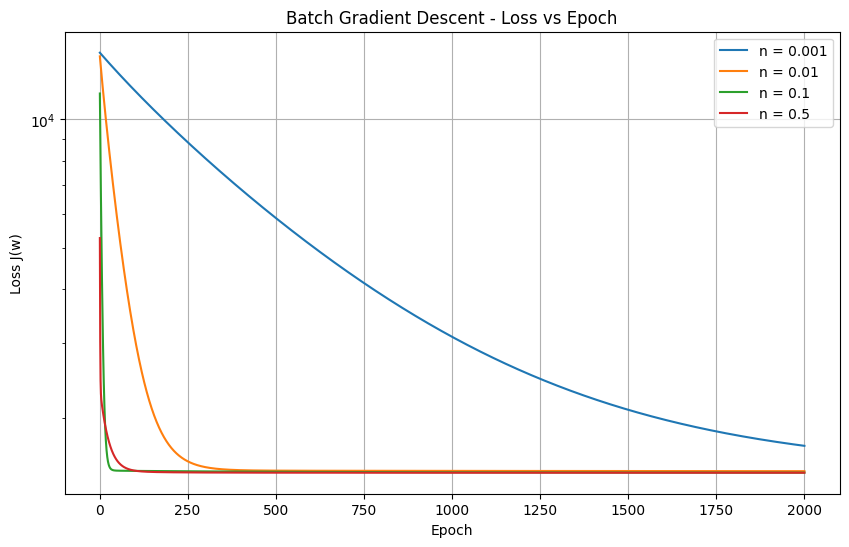

In [ ]:
# @title
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))

for n in [0.001, 0.01, 0.1, 0.5]:
    losses = gd_results[n]["losses"]
    plt.plot(range(1, 2001), losses, label=f"n = {n}")

plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Loss J(w)")
plt.title("Batch Gradient Descent - Loss vs Epoch")
plt.legend()
plt.grid(True)
plt.show()

i exclucde n=1.0 because loss is extremly large so it  made the other curves hard to read

In [ ]:

N=X_train_final.shape[0]
H=(X_train_final.T @ X_train_final)/N
eigenvalues=np.linalg.eigvalsh(H)
lambda_max=np.max(eigenvalues)
print("Largest eigenvalue:", lambda_max)
n_max = 2 / lambda_max
print("Maximum theoretical learning rate:", n_max)
#testing 2 diff learningrates around threshold
n_below = 0.95 * (2 / lambda_max)
n_above = 1.05 * (2 / lambda_max)
print("Learning rate below threshold:", n_below)
print("Learning rate above threshold:", n_above)

Largest eigenvalue: 3.9547550320503744
Maximum theoretical learning rate: 0.5057203249737277
Learning rate below threshold: 0.4804343087250412
Learning rate above threshold: 0.5310063412224141


#7 using raw data



Standardized Condition Number: 505.7061226960868
Standardized Maximum Learning Rate: 0.5057203249737277

Raw Condition Number: 55778473.21753785
Raw Maximum Learning Rate: 2.7427928748390996e-05

Learning Rate: 1e-08
Final Loss: 3583.5321022429885

Learning Rate: 1e-06
Final Loss: 2388.75258220855

Learning Rate: 1e-05
Final Loss: 1827.5349100578878

Learning Rate: 0.0001
Final Loss: nan


/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:83: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
/tmp/ipykernel_603/4021771879.py:52: RuntimeWarning: overflow encountered in square
  loss = np.sum((y_pred - y) ** 2) / (2 * N)
/tmp/ipykernel_603/4021771879.py:48: RuntimeWarning: overflow encountered in matmul
  gradient = (X.T @ (y_pred - y)) / N
/tmp/ipykernel_603/4021771879.py:49: RuntimeWarning: invalid value encountered in subtract
  w = w - n * gradient


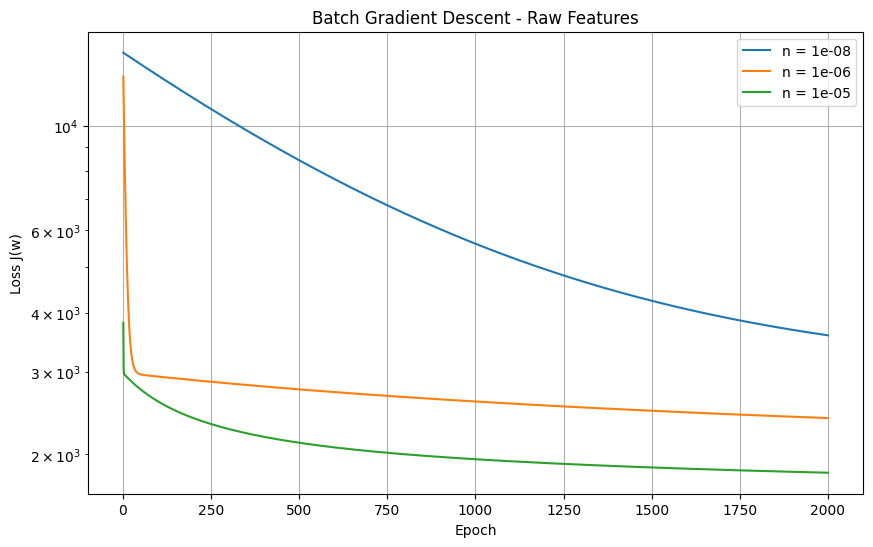

In [ ]:

# Now repeating without scaling

X_raw = X_diabetes

X_train_raw, X_val_raw, X_test_raw, y_train_raw, y_val_raw, y_test_raw = split_data(
    X_raw, y_diabetes, regression=True
)

# Add bias column
X_train_raw_final = np.column_stack((
    np.ones(X_train_raw.shape[0]), X_train_raw
))

X_val_raw_final = np.column_stack((
    np.ones(X_val_raw.shape[0]), X_val_raw
))

X_test_raw_final = np.column_stack((
    np.ones(X_test_raw.shape[0]), X_test_raw
))

#Calculate condition number and maximum learning rate
#Stand features
H_standard = (X_train_final.T @ X_train_final) / X_train_final.shape[0]

cond_standard = np.linalg.cond(X_train_final.T @ X_train_final)
lambda_standard = np.max(np.linalg.eigvalsh(H_standard))
n_max_standard = 2 / lambda_standard

#Raw features
H_raw = (X_train_raw_final.T @ X_train_raw_final) / X_train_raw_final.shape[0]

cond_raw = np.linalg.cond(X_train_raw_final.T @ X_train_raw_final)
lambda_raw = np.max(np.linalg.eigvalsh(H_raw))
n_max_raw = 2 / lambda_raw

print("Standardized Condition Number:", cond_standard)
print("Standardized Maximum Learning Rate:", n_max_standard)
print("\nRaw Condition Number:", cond_raw)
print("Raw Maximum Learning Rate:", n_max_raw)
#Batch Gradient Descent for raw features
def batch_gd_raw(X, y, n, epochs):
    N = X.shape[0]
    w = np.zeros(X.shape[1])
    losses = []
    for epoch in range(epochs):
        y_pred = X @ w
        gradient = (X.T @ (y_pred - y)) / N
        w = w - n * gradient

        y_pred = X @ w
        loss = np.sum((y_pred - y) ** 2) / (2 * N)
        losses.append(loss)
    return w, losses
#Run different learning rates
raw_learning_rates = [1e-8, 1e-6, 1e-5, 1e-4]
raw_results = {}
for n in raw_learning_rates:
    w, losses = batch_gd_raw(
        X_train_raw_final, y_train_raw, n, 2000
    )
    raw_results[n] = {
        "weights": w,
        "losses": losses
    }
    print("\nLearning Rate:", n)
    print("Final Loss:", losses[-1])
# Plot loss vs epochs used ai to make it clearer
plt.figure(figsize=(10, 6))
for n in [1e-8, 1e-6, 1e-5]:
    losses = np.array(raw_results[n]["losses"])

    plt.plot(
        range(1, len(losses) + 1),
        losses,
        label=f"n = {n}"
    )

plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Loss J(w)")
plt.title("Batch Gradient Descent - Raw Features")
plt.legend()
plt.grid(True)
plt.show()

When using raw features, the condition number increases significantly from about 506 to 55.8 million because the features have very different scales. This also reduces the maximum theoretical learning rate from 0.5057 to 0.00002743. As a result, we need much smaller learning rates, which make the updates slower and require more epochs to approach the optimal loss. In our experiment, none of the raw runs reached the optimal loss after 2000 epochs, and the learning rate 0.0001 caused Gradient Descent to diverge.


# 8 SGD and mini-batch

In [ ]:
def mini_batch_gd(X, y, n, epochs, B):
    N = X.shape[0]
    w = np.zeros(X.shape[1])

    epoch_losses = []
    update_losses = []

    rng = np.random.default_rng(42)

    for epoch in range(epochs):

        #Shuffle the training data
        indices = rng.permutation(N)
        X_shuffled = X[indices]
        y_shuffled = y[indices]

        #Divide the data into batches
        for start in range(0, N, B):
            end = min(start + B, N)

            X_batch = X_shuffled[start:end]
            y_batch = y_shuffled[start:end]

            #Calculate gradient using the current batch
            y_pred = X_batch @ w
            gradient = (X_batch.T @ (y_pred - y_batch)) / len(y_batch)

            #Update weights
            w = w - n * gradient

            #Calculate full training loss after each update
            y_train_pred = X @ w
            loss = np.sum((y_train_pred - y) ** 2) / (2 * N)
            update_losses.append(loss)

        #Calculate loss at the end of each epoch
        epoch_losses.append(update_losses[-1])

    return w, epoch_losses, update_losses


#Compare different batch sizes
N_train = X_train_final.shape[0]
batch_sizes = [1, 16, 64, N_train]

mini_batch_results = {}

for B in batch_sizes:
    w, epoch_losses, update_losses = mini_batch_gd(
        X_train_final, y_train, n=0.01, epochs=100, B=B
    )

    mini_batch_results[B] = {
        "weights": w,
        "epoch_losses": epoch_losses,
        "update_losses": update_losses
    }

    print("Batch size:", B)
    print("Final loss:", epoch_losses[-1])
    print("Number of updates:", len(update_losses))
    print()


Batch size: 1
Final loss: 1534.8083853085998
Number of updates: 26400

Batch size: 16
Final loss: 1505.665099007747
Number of updates: 1700

Batch size: 64
Final loss: 1511.3753357143576
Number of updates: 500

Batch size: 264
Final loss: 3085.440478999073
Number of updates: 100



#testing with tiny data

In [ ]:
X_sample = X_example[1]
y_sample = y_example[1]

w = np.zeros(X_example.shape[1])

gradient = X_sample * (X_sample @ w - y_sample)

w = w - n * gradient

print("SGD weights:", w)

expected = np.array([0.3, 0.6])

print("Passed:", np.allclose(w, expected))

SGD weights: [3.e-05 6.e-05]
Passed: False


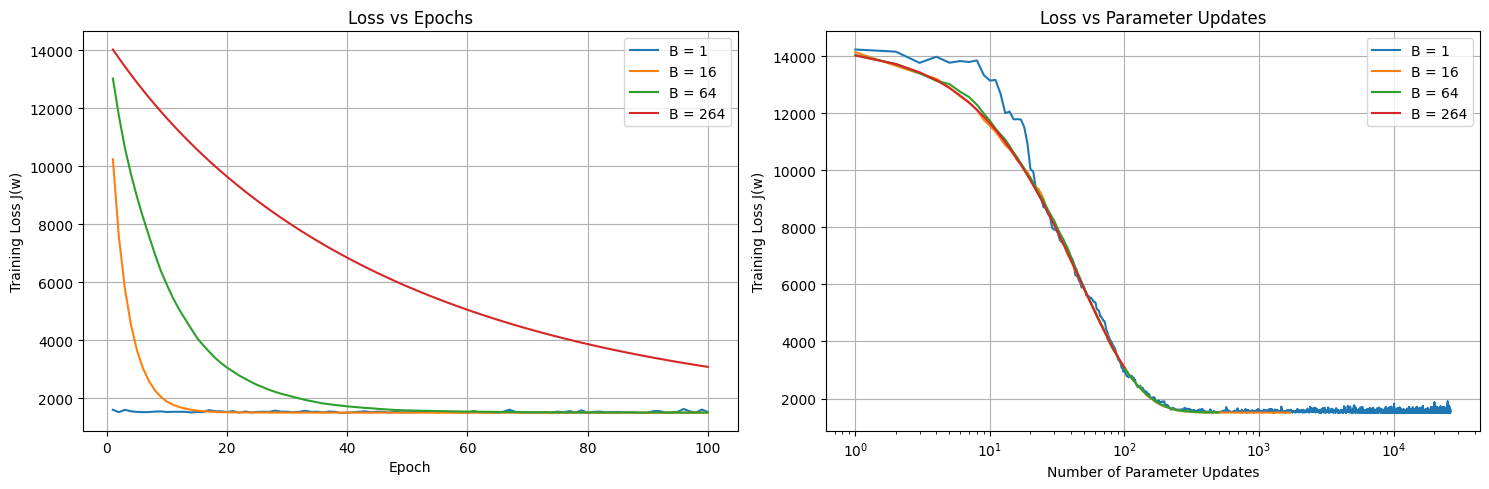

In [ ]:

#ai
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for B in batch_sizes:
    epoch_losses = mini_batch_results[B]["epoch_losses"]
    update_losses = mini_batch_results[B]["update_losses"]

    axes[0].plot(
        range(1, len(epoch_losses) + 1),
        epoch_losses,
        label=f"B = {B}"
    )

    axes[1].plot(
        range(1, len(update_losses) + 1),
        update_losses,
        label=f"B = {B}"
    )

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Training Loss J(w)")
axes[0].set_title("Loss vs Epochs")
axes[0].legend()
axes[0].grid(True)

axes[1].set_xlabel("Number of Parameter Updates")
axes[1].set_ylabel("Training Loss J(w)")
axes[1].set_title("Loss vs Parameter Updates")
axes[1].set_xscale("log")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()
#end ai

Learning rate: 0.001
Final loss: 1503.312176810556

Learning rate: 0.01
Final loss: 1534.8083853085998

Learning rate: 0.1
Final loss: 4186.980951940034



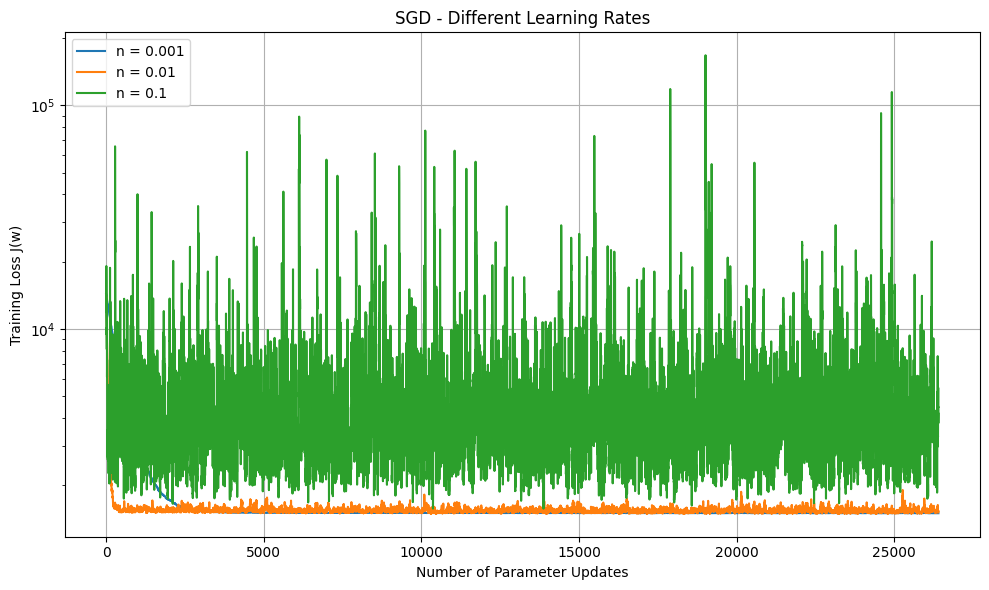

In [ ]:

#diif learning rates

sgd_learning_rates = [0.001, 0.01, 0.1]
sgd_results = {}

for n in sgd_learning_rates:
    w, epoch_losses, update_losses = mini_batch_gd(
        X_train_final, y_train, n=n, epochs=100, B=1
    )

    sgd_results[n] = {
        "weights": w,
        "epoch_losses": epoch_losses,
        "update_losses": update_losses
    }

    print("Learning rate:", n)
    print("Final loss:", epoch_losses[-1])
    print()
#ai
plt.figure(figsize=(10, 6))

for n in sgd_learning_rates:
    losses = sgd_results[n]["update_losses"]

    plt.plot(
        range(1, len(losses) + 1),
        losses,
        label=f"n = {n}"
    )

plt.xlabel("Number of Parameter Updates")
plt.ylabel("Training Loss J(w)")
plt.title("SGD - Different Learning Rates")
plt.yscale("log")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()
#end ai

In [ ]:
#ai
# Compare loss after the first 100 parameter updates

for B in batch_sizes:
    loss = mini_batch_results[B]["update_losses"][99]
    print("B =", B, "| Loss after 100 updates:", loss)
    #end ai

B = 1 | Loss after 100 updates: 2961.135619409692
B = 16 | Loss after 100 updates: 3087.863567909388
B = 64 | Loss after 100 updates: 3058.6846569536383
B = 264 | Loss after 100 updates: 3085.440478999073


I implemented Mini-batch Gradient Descent using different batch sizes: 1, 16, 64, and the full training set (264 samples). A batch size of 1 represents SGD, while a batch size of 264 represents regular Batch Gradient Descent.

After 100 epochs, batch size 16 achieved the lowest training loss (1505.67), followed by batch size 64 (1511.38). SGD achieved a final loss of 1534.81, while full Batch Gradient Descent achieved 3085.44. Therefore, B = 16 performed best per epoch.

When comparing the algorithms after the same number of parameter updates (100 updates), SGD (B = 1) achieved the lowest loss of 2961.14. However, this comparison does not mean it is more efficient overall, because each update uses only one sample.

SGD is noisier because it calculates the gradient using only one sample at a time. Each sample can give a different gradient direction, which causes fluctuations in the loss. Mini-batches reduce this noise by calculating the gradient using more samples.

When testing different learning rates with SGD, 0.001 achieved the lowest final loss (1503.31). Increasing the learning rate to 0.01 resulted in a slightly higher loss, while 0.1 produced a much higher loss (4186.98). This shows that larger learning rates can cause bigger updates and make SGD less stable.

## **9 Ridge (L2)**

### Ridge Regression (L2) – Derivation

We start with the Ridge Regression cost function:

$$
J_\lambda(w)=\frac{1}{2N}\|\widetilde{X}w-y\|^2+
\frac{\lambda}{2}\|w_{1:}\|^2
$$

Since the first weight is the bias, we do not penalize it. We can rewrite the cost function using a matrix:

$$
J_\lambda(w)=
\frac{1}{2N}(\widetilde{X}w-y)^T(\widetilde{X}w-y)
+\frac{\lambda}{2}w^TI_0w
$$

where \(I_0\) is the identity matrix with its first diagonal element set to zero.

**Step 1: Expand the cost function**

$$
\begin{aligned}
J_\lambda(w)=
&\frac{1}{2N}\left(
w^T\widetilde{X}^T\widetilde{X}w
-2y^T\widetilde{X}w
+y^Ty
\right)\\
&+\frac{\lambda}{2}w^TI_0w
\end{aligned}
$$

**Step 2: Calculate the gradient**

Taking the derivative with respect to \(w\):

$$
\nabla J_\lambda(w)=
\frac{1}{N}\widetilde{X}^T\widetilde{X}w
-\frac{1}{N}\widetilde{X}^Ty
+\lambda I_0w
$$

**Step 3: Set the gradient equal to zero**

At the minimum, the gradient is zero:

$$
\frac{1}{N}\widetilde{X}^T\widetilde{X}w
-\frac{1}{N}\widetilde{X}^Ty
+\lambda I_0w=0
$$

Rearranging:

$$
\left(
\frac{\widetilde{X}^T\widetilde{X}}{N}
+\lambda I_0
\right)w
=
\frac{\widetilde{X}^Ty}{N}
$$

**Step 4: Solve for the weights**

Multiplying both sides by the inverse matrix:

$$
\boxed{
w=
\left(
\frac{\widetilde{X}^T\widetilde{X}}{N}
+\lambda I_0
\right)^{-1}
\frac{\widetilde{X}^Ty}{N}
}
$$

This is the closed-form solution for Ridge Regression. The regularization term reduces the size of the feature weights, while keeping the bias unpenalized.

In [ ]:
def ridge_regression(X, y, lam):
    N = X.shape[0]
    I0 = np.eye(X.shape[1])
    I0[0, 0] = 0
    A = (X.T @ X) / N + lam * I0
    b = (X.T @ y) / N
    w = np.linalg.solve(A, b)
    return w

tiny data test

In [ ]:
w_ridge_example = ridge_regression(X_example, y_example, 1)
expected = np.array([32/15, 0.6])
print("Ridge weights:", w_ridge_example)
print("Expected weights:", expected)
print("Passed:", np.allclose(w_ridge_example, expected))

Ridge weights: [2.13333333 0.6       ]
Expected weights: [2.13333333 0.6       ]
Passed: True


In [ ]:
X_train_ridge = X_train_final
X_val_ridge = X_val_final
X_test_ridge = X_test_final

y_train_ridge = y_train
y_val_ridge = y_val
y_test_ridge = y_test

print("Training shape:", X_train_ridge.shape)
print("Validation shape:", X_val_ridge.shape)
print("Test shape:", X_test_ridge.shape)

Training shape: (264, 11)
Validation shape: (89, 11)
Test shape: (89, 11)


In [ ]:
#degree 2 expantion
def degree2_features(X):
    features = [X]

    for i in range(X.shape[1]):
        for j in range(i, X.shape[1]):
            # Skip sex squared because it is redundant
            if i == 1 and j == 1:
                continue
            features.append((X[:, i] * X[:, j]).reshape(-1, 1))
    return np.column_stack(features)


X_train_poly = degree2_features(X_train_raw)
X_val_poly = degree2_features(X_val_raw)
X_test_poly = degree2_features(X_test_raw)

print("Training shape:", X_train_poly.shape)
print("Validation shape:", X_val_poly.shape)
print("Test shape:", X_test_poly.shape)

Training shape: (264, 64)
Validation shape: (89, 64)
Test shape: (89, 64)


In [ ]:
#standrized
poly_mean = np.mean(X_train_poly, axis=0)
poly_std = np.std(X_train_poly, axis=0)

X_train_poly_scaled = (X_train_poly - poly_mean) / poly_std
X_val_poly_scaled = (X_val_poly - poly_mean) / poly_std
X_test_poly_scaled = (X_test_poly - poly_mean) / poly_std

X_train_poly_final = np.column_stack((
    np.ones(X_train_poly_scaled.shape[0]),
    X_train_poly_scaled
))
X_val_poly_final = np.column_stack((
    np.ones(X_val_poly_scaled.shape[0]),
    X_val_poly_scaled
))
X_test_poly_final = np.column_stack((
    np.ones(X_test_poly_scaled.shape[0]),
    X_test_poly_scaled
))
print("Training shape:", X_train_poly_final.shape)
print("Validation shape:", X_val_poly_final.shape)
print("Test shape:", X_test_poly_final.shape)

Training shape: (264, 65)
Validation shape: (89, 65)
Test shape: (89, 65)


In [ ]:
lambdas = np.concatenate(([0], np.logspace(-3, 1, 9)))
original_weights = []
original_val_rmse = []
original_test_rmse = []
for lam in lambdas:
    w = ridge_regression(X_train_ridge, y_train_ridge, lam)
    val_pred = X_val_ridge @ w
    test_pred = X_test_ridge @ w
    original_weights.append(w)
    original_val_rmse.append(rmse(y_val_ridge, val_pred))
    original_test_rmse.append(rmse(y_test_ridge, test_pred))
original_weights = np.array(original_weights)
original_val_rmse = np.array(original_val_rmse)
original_test_rmse = np.array(original_test_rmse)
print("Original features validation RMSE:")
for lam, error in zip(lambdas, original_val_rmse):
    print("Lambda:", lam, "| Validation RMSE:", error)

Original features validation RMSE:
Lambda: 0.0 | Validation RMSE: 51.19371397853391
Lambda: 0.001 | Validation RMSE: 51.14955605683115
Lambda: 0.0031622776601683794 | Validation RMSE: 51.10804077305131
Lambda: 0.01 | Validation RMSE: 51.10474905057183
Lambda: 0.03162277660168379 | Validation RMSE: 51.15313032738308
Lambda: 0.1 | Validation RMSE: 51.20730458401005
Lambda: 0.31622776601683794 | Validation RMSE: 51.577987730134396
Lambda: 1.0 | Validation RMSE: 53.69512357732541
Lambda: 3.1622776601683795 | Validation RMSE: 59.42033249227695
Lambda: 10.0 | Validation RMSE: 66.95464908854308


For the original 10 features, Ridge Regression only slightly improves the validation RMSE. The best lambda is 0.01, with a validation RMSE of 51.10 compared to 51.19 when lambda is zero. This means that regularization does not make a big difference for the original features.

In [ ]:
poly_weights = []
poly_val_rmse = []
poly_test_rmse = []
for lam in lambdas:
    w = ridge_regression(X_train_poly_final, y_train_ridge, lam)
    val_pred = X_val_poly_final @ w
    test_pred = X_test_poly_final @ w
    poly_weights.append(w)
    poly_val_rmse.append(rmse(y_val_ridge, val_pred))
    poly_test_rmse.append(rmse(y_test_ridge, test_pred))
poly_weights = np.array(poly_weights)
poly_val_rmse = np.array(poly_val_rmse)
poly_test_rmse = np.array(poly_test_rmse)
print("Expanded features validation RMSE:")
for lam, error in zip(lambdas, poly_val_rmse):
    print("Lambda:", lam, "| Validation RMSE:", error)

Expanded features validation RMSE:
Lambda: 0.0 | Validation RMSE: 59.20594938585084
Lambda: 0.001 | Validation RMSE: 54.20787063951586
Lambda: 0.0031622776601683794 | Validation RMSE: 53.05319398672029
Lambda: 0.01 | Validation RMSE: 52.106088519743935
Lambda: 0.03162277660168379 | Validation RMSE: 51.474169852197356
Lambda: 0.1 | Validation RMSE: 51.27063977293424
Lambda: 0.31622776601683794 | Validation RMSE: 51.316252274795964
Lambda: 1.0 | Validation RMSE: 51.49724346989616
Lambda: 3.1622776601683795 | Validation RMSE: 52.63019328265264
Lambda: 10.0 | Validation RMSE: 56.64033179006731


For the expanded features, Ridge Regression makes a much bigger difference. Without regularization, the validation RMSE is 59.21, which is much higher than the original model. The best lambda is 0.1, which reduces the validation RMSE to 51.27. This happens because the expanded model has more features and is more likely to overfit, so Ridge helps by reducing the size of the weights.

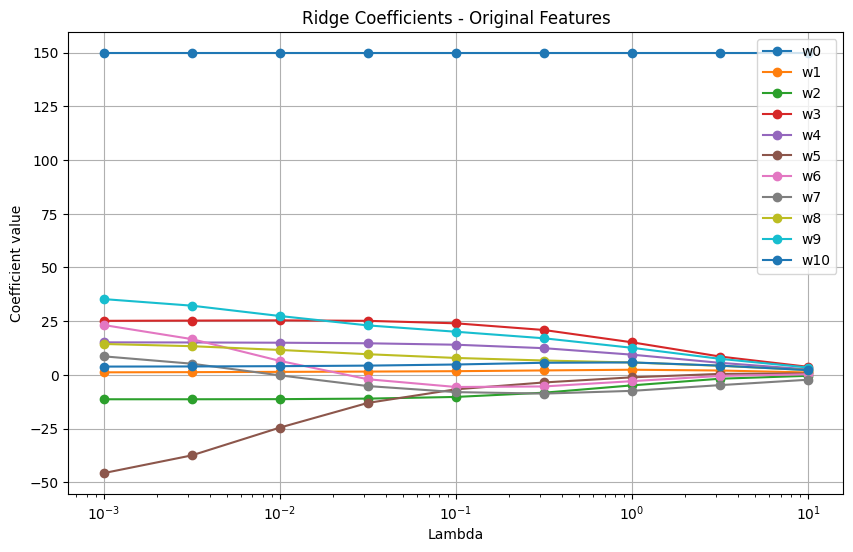

In [ ]:
positive_lambdas = lambdas[1:]
plt.figure(figsize=(10, 6))
for i in range(original_weights.shape[1]):
    plt.plot(positive_lambdas,original_weights[1:, i],marker='o',label=f"w{i}")
plt.xscale("log")
plt.xlabel("Lambda")
plt.ylabel("Coefficient value")
plt.title("Ridge Coefficients - Original Features")
plt.legend()
plt.grid(True)
plt.show()

As lambda increases, the feature coefficients generally become smaller and move closer to zero. This happens because Ridge Regression penalizes large weights. However, the bias stays almost constant because it is not included in the regularization term. This shows how Ridge controls the size of the coefficients to reduce overfitting.

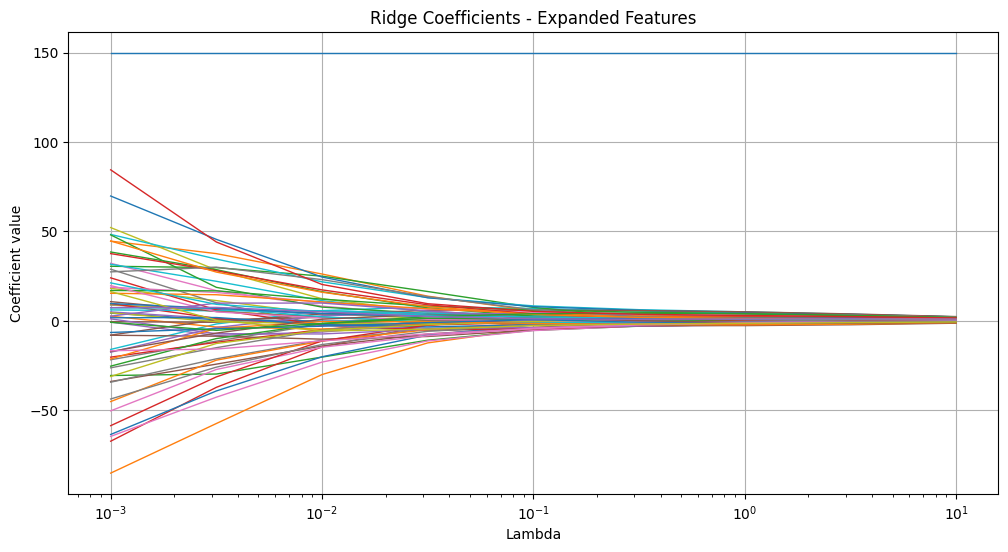

In [ ]:
#Expanded
plt.figure(figsize=(12, 6))

for i in range(poly_weights.shape[1]):
    plt.plot(positive_lambdas,poly_weights[1:, i],linewidth=1)
plt.xscale("log")
plt.xlabel("Lambda")
plt.ylabel("Coefficient value")
plt.title("Ridge Coefficients - Expanded Features")
plt.grid(True)
plt.show()

Lambda = 0
Original features validation RMSE: 51.19371397853391
Expanded features validation RMSE: 59.20594938585084


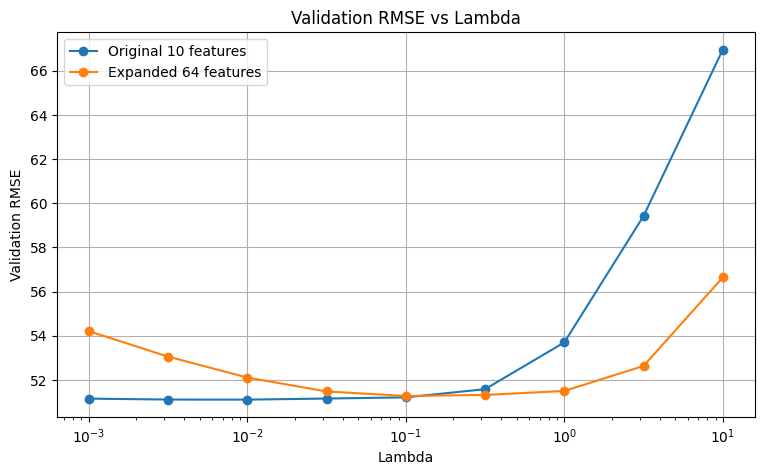

In [ ]:
plt.figure(figsize=(9, 5))
print("Lambda = 0")
print("Original features validation RMSE:", original_val_rmse[0])
print("Expanded features validation RMSE:", poly_val_rmse[0])
plt.plot(positive_lambdas,original_val_rmse[1:],marker='o',label="Original 10 features")
plt.plot(positive_lambdas,poly_val_rmse[1:],marker='o',label="Expanded 64 features")
plt.xscale("log")
plt.xlabel("Lambda")
plt.ylabel("Validation RMSE")
plt.title("Validation RMSE vs Lambda")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
best_original_index = np.argmin(original_val_rmse)
best_poly_index = np.argmin(poly_val_rmse)
best_original_lambda = lambdas[best_original_index]
best_poly_lambda = lambdas[best_poly_index]
print("Original features")
print("Best lambda:", best_original_lambda)
print("Best validation RMSE:", original_val_rmse[best_original_index])
print("Test RMSE at best lambda:", original_test_rmse[best_original_index])
print("Test RMSE at lambda = 0:", original_test_rmse[0])
print()
print("Expanded features")
print("Best lambda:", best_poly_lambda)
print("Best validation RMSE:", poly_val_rmse[best_poly_index])
print("Test RMSE at best lambda:", poly_test_rmse[best_poly_index])
print("Test RMSE at lambda = 0:", poly_test_rmse[0])

Original features
Best lambda: 0.01
Best validation RMSE: 51.10474905057183
Test RMSE at best lambda: 53.9584521494208
Test RMSE at lambda = 0: 54.15641293326043

Expanded features
Best lambda: 0.1
Best validation RMSE: 51.27063977293424
Test RMSE at best lambda: 53.615580116744916
Test RMSE at lambda = 0: 62.133373392810036


Ridge Regression does not improve the original 10-feature model much because we have 264 training samples and only 10 features, so the model is not very complex compared to the amount of data. However, after expanding the features to 64, the model becomes more complex and has a higher chance of overfitting, so Ridge helps by reducing the feature weights. The bias should not be penalized because it represents the starting value of the prediction, and penalizing it could unnecessarily affect the model's predictions

In [ ]:
#Ridge batch gd
def ridge_batch_gd(X, y, n, epochs, lam):
    N = X.shape[0]
    w = np.zeros(X.shape[1])

    I0 = np.eye(X.shape[1])
    I0[0, 0] = 0

    for epoch in range(epochs):
        y_pred = X @ w

        gradient = (X.T @ (y_pred - y)) / N + lam * (I0 @ w)

        w = w - n * gradient

    return w

In [ ]:
lam = 0.1
n = 0.4
epochs = 3000

w_closed = ridge_regression(X_train_ridge, y_train_ridge, lam)

w_gd = ridge_batch_gd(X_train_ridge,y_train_ridge,n,epochs,lam)
relative_distance = (np.linalg.norm(w_gd - w_closed)/np.linalg.norm(w_closed))
print("Closed-form weights:", w_closed)
print("GD weights:", w_gd)
print("Relative distance:", relative_distance)
print("Passed:", relative_distance < 1e-6)

Closed-form weights: [149.81060606   1.71520109 -10.27220329  24.00312667  14.036236
  -6.7220634   -5.63988748  -8.02979453   7.87619758  20.08247856
   4.82614217]
GD weights: [149.81060606   1.71520109 -10.27220329  24.00312667  14.036236
  -6.7220634   -5.63988748  -8.02979453   7.87619758  20.08247856
   4.82614217]
Relative distance: 8.35921888397673e-16
Passed: True


I compared the weights from Batch Gradient Descent with the closed-form Ridge solution using lambda = 0.1, learning rate = 0.4, and 3000 epochs. The relative distance was 8.36e-16, which is smaller than 1e-6. This confirms that Batch Gradient Descent successfully converged to the closed-form solution.

In [ ]:
from sklearn.linear_model import Ridge
ridge_sklearn = Ridge(
    alpha=lam * X_train_ridge.shape[0],
    fit_intercept=True
)
ridge_sklearn.fit(X_train_ridge[:, 1:], y_train_ridge)
w_sklearn = np.concatenate(([ridge_sklearn.intercept_],ridge_sklearn.coef_))
print("Our Ridge weights:", w_closed)
print("Sklearn Ridge weights:", w_sklearn)
print("Maximum difference:", np.max(np.abs(w_closed - w_sklearn)))
print("Passed:", np.allclose(w_closed, w_sklearn))

Our Ridge weights: [149.81060606   1.71520109 -10.27220329  24.00312667  14.036236
  -6.7220634   -5.63988748  -8.02979453   7.87619758  20.08247856
   4.82614217]
Sklearn Ridge weights: [149.81060606   1.71520109 -10.27220329  24.00312667  14.036236
  -6.7220634   -5.63988748  -8.02979453   7.87619758  20.08247856
   4.82614217]
Maximum difference: 1.5631940186722204e-13
Passed: True


I compared my Ridge Regression implementation with sklearn Ridge using alpha = lambda * N_train. Both implementations produced almost identical weights, with a maximum difference of 1.56e-13. This confirms that my Ridge implementation is correct.

In [ ]:
condition_original = np.linalg.cond(X_train_ridge.T @ X_train_ridge)
condition_poly = np.linalg.cond(
    X_train_poly_final.T @ X_train_poly_final
)

print("Original features condition number:", condition_original)
print("Expanded features condition number:", condition_poly)

Original features condition number: 505.7061226960868
Expanded features condition number: 1289356232.45045


#10 From scratch vs. frameworks

In [ ]:
X_train = X_train_final
X_test = X_test_final
y_train = y_train
y_test = y_test
N = X_train.shape[0]

In [ ]:
import time
#Normal Equation and LinearRegression
from sklearn.linear_model import LinearRegression
#Normal Equation from scratch
start = time.perf_counter()
w_normal = normal_equation(X_train, y_train)
normal_time = time.perf_counter() - start
normal_pred = X_test @ w_normal
normal_rmse = rmse(y_test, normal_pred)
#sklearn LinearRegression
start = time.perf_counter()
linear_model = LinearRegression()
linear_model.fit(X_train[:, 1:], y_train)
linear_time = time.perf_counter() - start
w_linear = np.concatenate(([linear_model.intercept_],linear_model.coef_))
linear_pred = linear_model.predict(X_test[:, 1:])
linear_rmse = rmse(y_test, linear_pred)
#compare weights
print("Maximum weight difference:",
      np.max(np.abs(w_normal - w_linear)))

Maximum weight difference: 1.1510792319313623e-12


In [ ]:
#batch gd
start = time.perf_counter()
w_batch, batch_losses, batch_distances = batch_gradient_descent(X_train, y_train, 0.5, 2000)
batch_time = time.perf_counter() - start
batch_pred = X_test @ w_batch
batch_rmse = rmse(y_test, batch_pred)
batch_relative_distance = (np.linalg.norm(w_batch - w_normal) /np.linalg.norm(w_normal))
print("Batch GD test RMSE:", batch_rmse)
print("Relative distance:", batch_relative_distance)
print("Fit time:", batch_time)

Batch GD test RMSE: 54.15625398075969
Relative distance: 0.0001546261648138314
Fit time: 0.1534416140000303


In [ ]:
#mini batch
start = time.perf_counter()
w_mini, mini_epoch_losses, mini_update_losses = mini_batch_gd(X_train, y_train, 0.01, 100, 16)
mini_time = time.perf_counter() - start
mini_pred = X_test @ w_mini
mini_rmse = rmse(y_test, mini_pred)
mini_relative_distance = (np.linalg.norm(w_mini - w_normal)/np.linalg.norm(w_normal))
print("Mini-batch GD test RMSE:", mini_rmse)
print("Relative distance:", mini_relative_distance)
print("Fit time:", mini_time)

Mini-batch GD test RMSE: 53.895448565504836
Relative distance: 0.342147090232231
Fit time: 0.21842599399997198


In [ ]:
lam = 0.1
# Ridge from scratch
start = time.perf_counter()
w_ridge = ridge_regression(X_train, y_train, lam)
ridge_time = time.perf_counter() - start
ridge_pred = X_test @ w_ridge
ridge_rmse = rmse(y_test, ridge_pred)
ridge_relative_distance = (np.linalg.norm(w_ridge - w_ridge) /np.linalg.norm(w_ridge))
# sklearn Ridge
from sklearn.linear_model import Ridge
start = time.perf_counter()
ridge_model = Ridge(alpha=lam * N,fit_intercept=True)
ridge_model.fit(X_train[:, 1:], y_train)
sklearn_ridge_time = time.perf_counter() - start
w_sklearn_ridge = np.concatenate(([ridge_model.intercept_],ridge_model.coef_))
sklearn_ridge_pred = ridge_model.predict(X_test[:, 1:])
sklearn_ridge_rmse = rmse(y_test, sklearn_ridge_pred)
sklearn_ridge_relative_distance = (np.linalg.norm(w_sklearn_ridge - w_ridge) /np.linalg.norm(w_ridge))
print("Maximum weight difference:",np.max(np.abs(w_ridge - w_sklearn_ridge)))

Maximum weight difference: 1.5631940186722204e-13


In [ ]:
from sklearn.linear_model import SGDRegressor

sgd_results = []

for n in [0.001, 0.01, 0.1]:
    sgd_model = SGDRegressor(penalty=None,learning_rate="constant",eta0=n,max_iter=1000,tol=None,random_state=42)
    start = time.perf_counter()
    sgd_model.fit(X_train[:, 1:], y_train)
    fit_time = time.perf_counter() - start
    w_sgd = np.concatenate(([sgd_model.intercept_[0]],sgd_model.coef_))
    sgd_pred = sgd_model.predict(X_test[:, 1:])
    sgd_test_rmse = rmse(y_test, sgd_pred)
    relative_distance = (np.linalg.norm(w_sgd - w_normal) /np.linalg.norm(w_normal))
    sgd_results.append({"Method": f"SGDRegressor (eta0={n})","Test RMSE": sgd_test_rmse,"Relative Distance": relative_distance,"Fit Time (seconds)": fit_time})
    print("Learning rate:", n)
    print("Test RMSE:", sgd_test_rmse)
    print("Relative distance:", relative_distance)
    print("Fit time:", fit_time)
    print()

Learning rate: 0.001
Test RMSE: 54.088485882768005
Relative distance: 0.049760502941369585
Fit time: 0.060520257000007405

Learning rate: 0.01
Test RMSE: 54.89806109098834
Relative distance: 0.05031992571850522
Fit time: 0.03398168299997906

Learning rate: 0.1
Test RMSE: 71.44934756029937
Relative distance: 0.39496849805626943
Fit time: 0.027857407999931638



In [ ]:
#ai
results = [
    {
        "Method": "Normal Equation",
        "Test RMSE": normal_rmse,
        "Relative Distance": 0.0,
        "Fit Time (seconds)": normal_time
    },
    {
        "Method": "Batch GD",
        "Test RMSE": batch_rmse,
        "Relative Distance": batch_relative_distance,
        "Fit Time (seconds)": batch_time
    },
    {
        "Method": "Mini-batch GD (B=16)",
        "Test RMSE": mini_rmse,
        "Relative Distance": mini_relative_distance,
        "Fit Time (seconds)": mini_time
    },
    {
        "Method": "Ridge (from scratch)",
        "Test RMSE": ridge_rmse,
        "Relative Distance": 0.0,
        "Fit Time (seconds)": ridge_time
    },
    {
        "Method": "LinearRegression",
        "Test RMSE": linear_rmse,
        "Relative Distance": (
            np.linalg.norm(w_linear - w_normal) /
            np.linalg.norm(w_normal)
        ),
        "Fit Time (seconds)": linear_time
    },
    {
        "Method": "Ridge (sklearn)",
        "Test RMSE": sklearn_ridge_rmse,
        "Relative Distance": sklearn_ridge_relative_distance,
        "Fit Time (seconds)": sklearn_ridge_time }
]
results.extend(sgd_results)
comparison_df = pd.DataFrame(results)
comparison_df

,Method,Test RMSE,Relative Distance,Fit Time (seconds)
0,Normal Equation,54.156413,0.000000e+00,0.003976
1,Batch GD,54.156254,1.546262e-04,0.153442
2,Mini-batch GD (B=16),53.895449,3.421471e-01,0.218426
3,Ridge (from scratch),53.708925,0.000000e+00,0.000428
4,LinearRegression,54.156413,9.868552e-15,0.013156
5,Ridge (sklearn),53.708925,1.522184e-15,0.002725
6,SGDRegressor (eta0=0.001),54.088486,4.976050e-02,0.060520
7,SGDRegressor (eta0=0.01),54.898061,5.031993e-02,0.033982
8,SGDRegressor (eta0=0.1),71.449348,3.949685e-01,0.027857


The Normal Equation and sklearn LinearRegression give almost identical results, and the same happens with my Ridge implementation and sklearn Ridge. Batch GD gets very close to the Normal Equation solution, while Mini-batch GD and SGDRegressor have some differences because they use iterative updates instead of solving the problem directly. For SGDRegressor, the learning rate has a clear effect on the results: a larger learning rate makes the updates less stable and leads to a higher test RMSE.

# **Part C : Logistic Regression:**

#11-Derivation and stable implementation:

In [ ]:
X_train, X_val, X_test, y_train, y_val, y_test = processed_data["Breast Cancer"]
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)
print(np.unique(y_train))
print(np.bincount(y_train))

Train: (341, 31)
Validation: (114, 31)
Test: (114, 31)
[0 1]
[214 127]


In [ ]:
def sigmoid(z):
    result = np.empty_like(z, dtype=float)
    positive = z >= 0
    result[positive] = 1 / (1 + np.exp(-z[positive]))
    exp_z = np.exp(z[~positive])
    result[~positive] = exp_z / (1 + exp_z) #for numerical stability
    return result

def loss(X, y, w, lambdaR):
    z = X @ w #multiplication matrix
    loss = np.mean(np.logaddexp(0, z) - y * z) #better for numerical stability
    reg = (lambdaR/2) * np.sum(w[1:] ** 2) #exclude bias from reg
    return loss+reg

def gradient(X, y, w, lambdaR):
    p = sigmoid(X @ w)
    grad = X.T @ (p - y) / len(y) #calc gd for each wt
    grad[1:] += lambdaR * w[1:] #exclude bias from reg
    return grad

In [ ]:
z = np.array([800.0, -800.0]) #Stable implementation experiment
y_test_values = np.array([1.0, 0.0])
sig = sigmoid(z)
stable_loss = np.logaddexp(0, z) - y_test_values * z

print("Sigmoid:", sig)
print("Stable loss:", stable_loss)

with np.errstate(over='ignore', divide='ignore', invalid='ignore'):
    naiveSigmoid = 1 / (1 + np.exp(-z))
    naiveLoss = -( #Theoretical formulas for sigmoid and bin CE
        y_test_values * np.log(naiveSigmoid) +
        (1 - y_test_values) * np.log(1- naiveSigmoid))
print("Naive probabilities:", naiveSigmoid)
print("Naive loss:", naiveLoss) #nan means numerical problem took place

Sigmoid: [1. 0.]
Stable loss: [0. 0.]
Naive probabilities: [1. 0.]
Naive loss: [nan nan]


In [ ]:
rng = np.random.default_rng(42) #generate random numbers
w_random = rng.normal(0, 0.1, X_train.shape[1]) #generate random weights
lambdaR = 0.1
def func(w):
    return loss(X_train, y_train, w, lambdaR)
def grad(w):
    return gradient(X_train, y_train, w, lambdaR)
error = grad_check(func, grad, w_random)
print("Gradient relative error:", error)

Gradient relative error: 1.899324633360124e-11


#12-Training and regularization:

In [ ]:
def train_logistic(X_train,y_train,X_val,y_val,lambdaR,learning_rate,epochs):
    w = np.zeros(X_train.shape[1])
    train_losses = []
    val_losses = []
    train_accuracies = []
    val_accuracies = []

    for epoch in range(epochs):
        grad = gradient(X_train, y_train, w, lambdaR)
        w = w - learning_rate * grad

        train_loss = loss(X_train, y_train, w, lambdaR)
        val_loss = loss(X_val, y_val, w, lambdaR)

        train_pred = (sigmoid(X_train @ w) >= 0.5).astype(int)
        val_pred = (sigmoid(X_val @ w) >= 0.5).astype(int)

        train_acc = accuracy(y_train, train_pred)
        val_acc = accuracy(y_val, val_pred)

        train_losses.append(train_loss)
        val_losses.append(val_loss)

        train_accuracies.append(train_acc)
        val_accuracies.append(val_acc)

    return w, train_losses, val_losses, train_accuracies, val_accuracies

In [ ]:
lambdas = [0, 1e-3, 1e-2, 1e-1, 1]
results = {}
for lambdaR in lambdas:
    w, train_losses, val_losses, train_accs, val_accs = train_logistic(
        X_train, y_train,
        X_val, y_val,
        lambdaR=lambdaR,
        learning_rate=0.5,
        epochs=3000
    )
    results[lambdaR] = {
        "w": w,
        "train_losses": train_losses,
        "val_losses": val_losses,
        "train_accs": train_accs,
        "val_accs": val_accs
    }
print("Done for all lambdas.")

Done for all lambdas.


In [ ]:
import pandas as pd
table_data = []
for lambdaR in lambdas:
    w = results[lambdaR]["w"]

    train_acc = results[lambdaR]["train_accs"][-1] #-1 get the list's last element
    val_acc = results[lambdaR]["val_accs"][-1]
    val_loss = results[lambdaR]["val_losses"][-1]
    weight_norm = np.linalg.norm(w[1:])

    table_data.append({
        "Lambda": lambdaR,
        "Train Accuracy": train_acc,
        "Validation Accuracy": val_acc,
        "Validation Loss": val_loss,
        "||w[1:]||": weight_norm})

results_table = pd.DataFrame(table_data)
results_table

,Lambda,Train Accuracy,Validation Accuracy,Validation Loss,||w[1:]||
0,0.000,0.994135,0.973684,0.084192,8.132231
1,0.001,0.988270,0.973684,0.086207,5.099928
2,0.010,0.985337,0.973684,0.110010,2.325749
3,0.100,0.973607,0.973684,0.202665,1.105547
4,1.000,0.938416,0.956140,0.389668,0.441485


In [ ]:
def get_val_loss(lam):
    return results[lam]["val_losses"][-1]
best_lambda = min(lambdas, key=get_val_loss)

best_w = results[best_lambda]["w"]
test_pred = (sigmoid(X_test @ best_w) >= 0.5).astype(int)
test_acc = accuracy(y_test, test_pred)

print("Best Lambda:", best_lambda)
print("Test Accuracy:", test_acc)

Best Lambda: 0
Test Accuracy: 0.9736842105263158


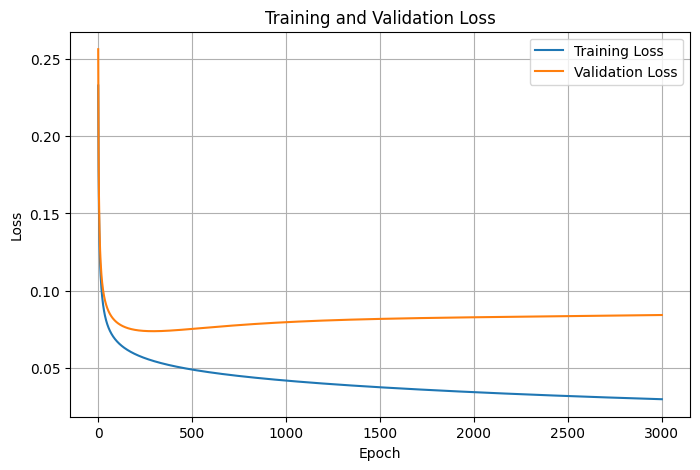

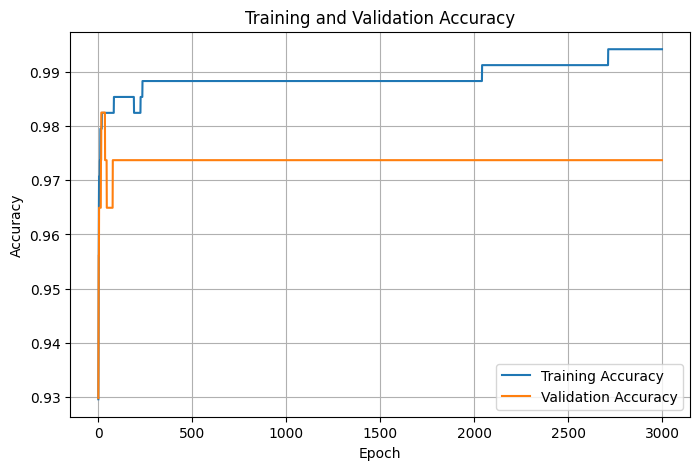

In [ ]:
import matplotlib.pyplot as plt
best_results = results[best_lambda]
epochs_range = range(1, 3001)

plt.figure(figsize=(8, 5))
plt.plot(epochs_range, best_results["train_losses"], label="Training Loss")
plt.plot(epochs_range, best_results["val_losses"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid()
plt.show()


plt.figure(figsize=(8, 5))
plt.plot(epochs_range, best_results["train_accs"], label="Training Accuracy")
plt.plot(epochs_range, best_results["val_accs"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid()
plt.show()

In [ ]:
learning_rates = [0.01, 0.1, 1, 5, 20]
lr_results = {}

for lRate in learning_rates:
    w, train_losses, val_losses, train_accs, val_accs = train_logistic(
        X_train, y_train,
        X_val, y_val,
        lambdaR=0.01,
        learning_rate=lRate,
        epochs=1000)

    lr_results[lRate] = train_losses[-1]

    lr_table = pd.DataFrame({
    "Learning Rate": lr_results.keys(),
    "Final Training Loss": lr_results.values()})
lr_table

,Learning Rate,Final Training Loss
0,0.01,0.116289
1,0.10,0.098311
2,1.00,0.098112
3,5.00,0.098112
4,20.00,0.157823


## Sanity Checks

1. **Over-regularization:** λ = 1 is over-regularized, as its validation loss (0.3897) is about 4.6 times larger than the best validation loss (0.0842).

2. **Under-training:** η = 0.01 is still under-trained after 1000 epochs, as its final training loss (0.1163) is higher than the losses obtained with larger learning rates.

3. **Failure to converge:** η = 20 fails to converge properly, as its final training loss (0.1578) is much higher than the losses obtained with η = 1 and η = 5.

#13-Separability:

In [ ]:
w_sep = np.zeros(X_train.shape[1])
weight_norms = []
train_losses = []

for epoch in range(20000):
    grad =gradient(X_train, y_train, w_sep, lambdaR=0)
    w_sep = w_sep - 0.5 * grad
    weight_norms.append(np.linalg.norm(w_sep[1:]))
    train_losses.append(loss(X_train, y_train, w_sep, lambdaR=0))

print("Final Weight Norm:", weight_norms[-1])
print("Final Training Loss:", train_losses[-1])

Final Weight Norm: 19.07910409109684
Final Training Loss: 0.011458238949846756


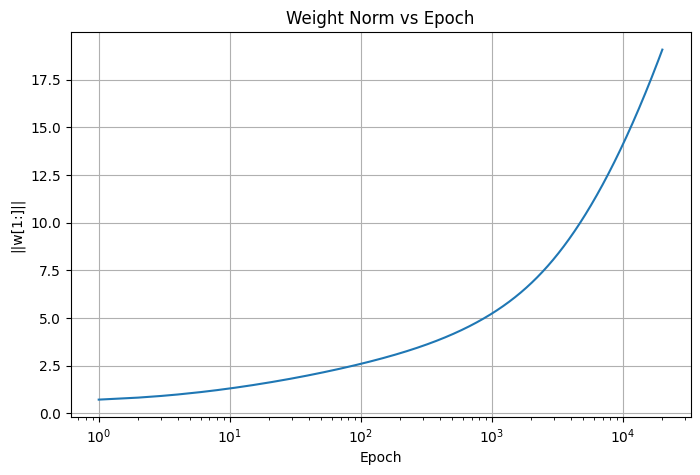

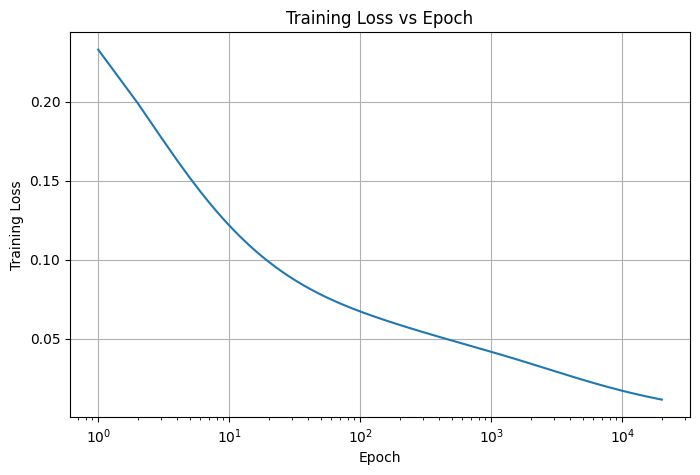

In [ ]:
epochs_range = np.arange(1, 20001)

plt.figure(figsize=(8, 5))
plt.plot(epochs_range, weight_norms)
plt.xscale("log")
plt.xlabel("Epoch")
plt.ylabel("||w[1:]||")
plt.title("Weight Norm vs Epoch")
plt.grid()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(epochs_range, train_losses)
plt.xscale("log")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss vs Epoch")
plt.grid()
plt.show()

##Makrdown:
The training set appears to be linearly separable based on the curves:

- The weight norm keeps increasing, reaching 19.08 after 20,000 epochs.
- The training loss keeps decreasing, reaching 0.01146.

For linearly separable data, the logistic loss approaches zero as the weights grow in the direction that correctly separates the classes. However, it never reaches zero for any finite weight values. Therefore, the unregularized loss has no finite minimizer.

L2 regularization fixes this by adding a penalty for large weights, preventing them from growing without bound and encouraging a finite, stable solution.

#14-Off-the-shelf comparison:


In [ ]:
from sklearn.linear_model import LogisticRegression
sklearn_results = {}
sklearn_data = []

for lambdaR in lambdas:
    if lambdaR == 0:
        C = None
        model = LogisticRegression(
            penalty=None,
            max_iter=100000)
    else:
        C = 1 / (lambdaR * len(y_train))
        model = LogisticRegression(
            C=C,
            max_iter=100000)

    model.fit(X_train[:, 1:], y_train)

    train_acc = model.score(X_train[:, 1:], y_train)
    val_acc = model.score(X_val[:, 1:], y_val)
    test_acc = model.score(X_test[:, 1:], y_test)

    sklearn_results[lambdaR] = model

    sklearn_data.append([
        lambdaR, C, train_acc, val_acc, test_acc
    ])

sklearn_table = pd.DataFrame(
    sklearn_data,
    columns=["Lambda", "C", "Train Accuracy", "Validation Accuracy", "Test Accuracy"]
)

sklearn_table

,Lambda,C,Train Accuracy,Validation Accuracy,Test Accuracy
0,0.000,NaN,1.000000,0.964912,0.964912
1,0.001,2.932551,0.988270,0.973684,0.973684
2,0.010,0.293255,0.985337,0.973684,0.982456
3,0.100,0.029326,0.973607,0.973684,0.973684
4,1.000,0.002933,0.938416,0.956140,0.921053


In [ ]:
lambdaR = 0.01
model = LogisticRegression(
    C=1 / (lambdaR * len(y_train)),
    tol=1e-12,
    max_iter=100000)

model.fit(X_train[:, 1:], y_train)
w_sklearn = np.concatenate([model.intercept_, model.coef_.ravel()])
w_ours = results[lambdaR]["w"]

relative_error = np.linalg.norm(w_ours - w_sklearn) / np.linalg.norm(w_sklearn)
pred_ours = (sigmoid(X_test @ w_ours) >= 0.5).astype(int)
pred_sklearn = model.predict(X_test[:, 1:])

comparison_table = pd.DataFrame({
    "My Weights": w_ours,
    "Sklearn Weights": w_sklearn})
comparison_table.loc["Relative Error"] = [relative_error, relative_error]
comparison_table.loc["Predictions Agree"] = [
    np.array_equal(pred_ours, pred_sklearn),
    np.array_equal(pred_ours, pred_sklearn)] #1 means true
comparison_table

,My Weights,Sklearn Weights
0,-4.238164e-01,-4.238167e-01
1,4.527278e-01,4.527281e-01
2,4.263065e-01,4.263067e-01
3,4.391387e-01,4.391390e-01
4,4.380496e-01,4.380496e-01
5,2.973592e-01,2.973593e-01
6,-2.913227e-02,-2.913226e-02
7,4.805077e-01,4.805073e-01
8,6.841554e-01,6.841551e-01
9,-6.778635e-02,-6.778639e-02


In [ ]:
C_values = [0.001, 0.01, 0.1, 1, 10, 100, 1000]
C_results = []

for C in C_values:
    model = LogisticRegression(C=C, max_iter=100000)
    model.fit(X_train[:, 1:], y_train)
    C_results.append([
        C,
        model.score(X_train[:, 1:], y_train),
        model.score(X_val[:, 1:], y_val),
        model.score(X_test[:, 1:], y_test)])

C_table = pd.DataFrame(
    C_results,
    columns=["C", "Train Accuracy", "Validation Accuracy", "Test Accuracy"]
)
C_table

,C,Train Accuracy,Validation Accuracy,Test Accuracy
0,0.001,0.879765,0.903509,0.868421
1,0.010,0.950147,0.964912,0.947368
2,0.100,0.979472,0.982456,0.982456
3,1.000,0.988270,0.973684,0.973684
4,10.000,0.997067,0.964912,0.964912
5,100.000,1.000000,0.956140,0.956140
6,1000.000,1.000000,0.947368,0.956140


In [ ]:
import time
C = 1 / (0.01 * len(y_train))
solvers = ["lbfgs", "liblinear", "saga"]
solver_results = {}
solver_data = []

for solver in solvers:
    model = LogisticRegression(
        C=C,
        solver=solver,
        tol=1e-8,
        max_iter=100000)

    start = time.perf_counter()
    model.fit(X_train[:, 1:], y_train)
    elapsed = time.perf_counter() - start
    coefficients = np.concatenate([model.intercept_, model.coef_.ravel()])
    solver_results[solver] = coefficients

    solver_data.append([
        solver,
        model.n_iter_[0],
        elapsed,
        coefficients ])

for row in solver_data:
    difference = np.linalg.norm(
        solver_results[row[0]] - solver_results["lbfgs"])
    row.append(difference)

solver_table = pd.DataFrame(
    solver_data,
    columns=[
        "Solver",
        "Iterations",
        "Time (seconds)",
        "Coefficients",
        "Difference from lbfgs"])
solver_table

,Solver,Iterations,Time (seconds),Coefficients,Difference from lbfgs
0,lbfgs,28,0.013218,"[-0.4238167608567531, 0.4527281567456261, 0.42...",0.000000
1,liblinear,10,0.005875,"[-0.28790000564117296, 0.4411421155073194, 0.4...",0.162653
2,saga,783,0.212626,"[-0.42381641679413706, 0.452727744249599, 0.42...",0.000002


#Solver Comparison

We compared lbfgs, liblinear, and saga using the same regularization parameter (C = 1/0.01NTrain).

lbfgs: Converged in 28 iterations and took approximately 0.014 seconds.

liblinear: Converged in only 10 iterations and was the fastest solver, taking approximately 0.004 seconds. However, its coefficients differ from lbfgs, with a difference of approximately 0.162653.

saga: Took 774 iterations and approximately 0.317 seconds. Its coefficients are almost identical to lbfgs, with a difference of approximately 0.000002.

Effect of penalizing the intercept:

Unlike lbfgs and saga, liblinear also applies regularization to the intercept by representing it as a synthetic feature. This penalizes the intercept and pushes its value toward zero, which can change the decision boundary and produce different coefficients and predictions.

#Sanity Checks

The results of the C sweep satisfy the expected behavior:

When (C = 0.001), the model is clearly underfitting, as both training and validation accuracies are relatively low.

For (C >= 100), training accuracy reaches 1.0, while validation accuracy decreases. This indicates overfitting because the model fits the training data perfectly but generalizes less effectively to unseen data.

#15-Evaluation beyond accuracy:

In [ ]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score
w_001 = results[0.01]["w"]

test_scores = sigmoid(X_test @ w_001)
test_pred_0_5 = (test_scores >= 0.5).astype(int)

cm_0_5 = confusion_matrix(y_test, test_pred_0_5)
precision_0_5 = precision_score(y_test, test_pred_0_5)
recall_0_5 = recall_score(y_test, test_pred_0_5)
f1_0_5 = f1_score(y_test, test_pred_0_5)

print("Confusion Matrix:")
print(cm_0_5)
print("Precision:", precision_0_5)
print("Recall:", recall_0_5)
print("F1 Score:", f1_0_5)

Confusion Matrix:
[[72  0]
 [ 2 40]]
Precision: 1.0
Recall: 0.9523809523809523
F1 Score: 0.975609756097561


AUC from scratch: 0.9957418932197839
AUC from sklearn: 0.9957418932197838
Absolute Difference: 1.1102230246251565e-16


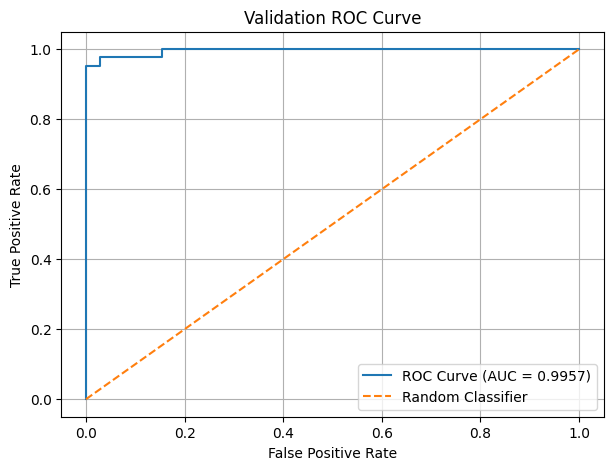

In [ ]:
from sklearn.metrics import roc_auc_score
val_scores = sigmoid(X_val @ w_001)

sorted_indices = np.argsort(-val_scores)
sorted_scores = val_scores[sorted_indices]
sorted_y = y_val[sorted_indices]

accum_tp = np.cumsum(sorted_y)
accum_fp = np.cumsum(1 - sorted_y)

distinct_indices = np.where(np.diff(sorted_scores) != 0)[0]
distinct_indices = np.append(distinct_indices, len(sorted_scores) - 1)

tp = accum_tp[distinct_indices]
fp = accum_fp[distinct_indices]

tpr = np.concatenate([[0], tp / np.sum(y_val)]) #True +ve Rate
fpr = np.concatenate([[0], fp / np.sum(1 - y_val)]) #False +ve Rate

auc_scratch = np.trapezoid(tpr, fpr) #auc=area under curve
auc_sklearn = roc_auc_score(y_val, val_scores)
assert abs(auc_scratch - auc_sklearn) < 1e-6

print("AUC from scratch:", auc_scratch)
print("AUC from sklearn:", auc_sklearn)
print("Absolute Difference:", abs(auc_scratch - auc_sklearn))

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {auc_scratch:.4f})")
plt.plot([0, 1], [0, 1], "--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Validation ROC Curve")
plt.legend()
plt.grid()
plt.show()

In [ ]:
tau = np.min(val_scores[y_val == 1])

val_pred_tau = (val_scores >= tau).astype(int)
val_recall_tau = recall_score(y_val, val_pred_tau)

test_pred_tau = (test_scores >= tau).astype(int)

cm_tau = confusion_matrix(y_test, test_pred_tau)
precision_tau = precision_score(y_test, test_pred_tau, zero_division=0)
recall_tau = recall_score(y_test, test_pred_tau)

threshold_table = pd.DataFrame({
    "Threshold": [0.5, tau],
    "Test Precision": [precision_0_5, precision_tau],
    "Test Recall": [recall_0_5, recall_tau]
}, index=["Default Threshold", "Selected Threshold"])

confusion_table = pd.DataFrame(
    [cm_0_5.ravel(), cm_tau.ravel()],
    index=["Threshold 0.5", "Selected Threshold"],
    columns=["TN", "FP", "FN", "TP"]
)

print("Validation Recall at Selected Threshold:", val_recall_tau)

display(threshold_table)
display(confusion_table)

Validation Recall at Selected Threshold: 1.0


,Threshold,Test Precision,Test Recall
Default Threshold,0.500000,1.00000,0.952381
Selected Threshold,0.146025,0.87234,0.976190


,TN,FP,FN,TP
Threshold 0.5,72,0,2,40
Selected Threshold,66,6,1,41


#### Threshold Selection

We selected the largest threshold \(tau\) that achieves a validation recall of 1 by taking the minimum predicted score among the actual positive (malignant) validation samples.

This ensures that all malignant cases in the validation set are classified as positive. We then applied the selected threshold to the test set and compared its confusion matrix, precision, and recall with the results obtained using the default threshold of 0.5.

#### False Negatives and False Positives

A false negative may delay cancer diagnosis and treatment, making it very dangerous. A false positive may cause unnecessary anxiety and medical tests. We should not fully trust the selected threshold because it was tuned using only 43 positive validation samples. It may not achieve 100% recall on new, unseen data.

#16-The boundary in original coordinates:

In [ ]:
feature_indices = [0,1]

X_train_raw = splits["Breast Cancer"][0][:, feature_indices]
X_val_raw = splits["Breast Cancer"][1][:, feature_indices]
X_test_raw = splits["Breast Cancer"][2][:, feature_indices]

scaler_2 = Standardizer()
scaler_2.fit(X_train_raw)

X_train_2 = add_bias(scaler_2.transform(X_train_raw))
X_val_2 = add_bias(scaler_2.transform(X_val_raw))
X_test_2 = add_bias(scaler_2.transform(X_test_raw))

print("Train shape:", X_train_2.shape)
print("Mean:", scaler_2.mean)
print("Std:", scaler_2.std)

Train shape: (341, 3)
Mean: [14.16341935 19.42876833]
Std: [3.5940381  4.35476066]


In [ ]:
w_2 = np.zeros(X_train_2.shape[1])
for epoch in range(5000):
    grad=gradient(X_train_2, y_train, w_2, lambdaR=0)
    w_2 = w_2 - 0.5 * grad
print("Weights:", w_2)

Weights: [-0.7271724   3.65679417  1.00987153]


In [ ]:
w_orig = np.zeros_like(w_2)
w_orig[1:] = w_2[1:] / scaler_2.std
w_orig[0] = w_2[0] - np.sum(
    w_2[1:] * scaler_2.mean / scaler_2.std)
print("Original weights:", w_orig)

Original weights: [-19.64344417   1.01746116   0.23190058]


In [ ]:
scores_standardized = X_test_2 @ w_2
scores_original = add_bias(X_test_raw) @ w_orig
max_difference = np.max(
    np.abs(scores_standardized - scores_original))
print("Maximum difference:", max_difference)
print("Verification passed:", max_difference < 1e-9)
assert max_difference < 1e-9

Maximum difference: 3.552713678800501e-15
Verification passed: True


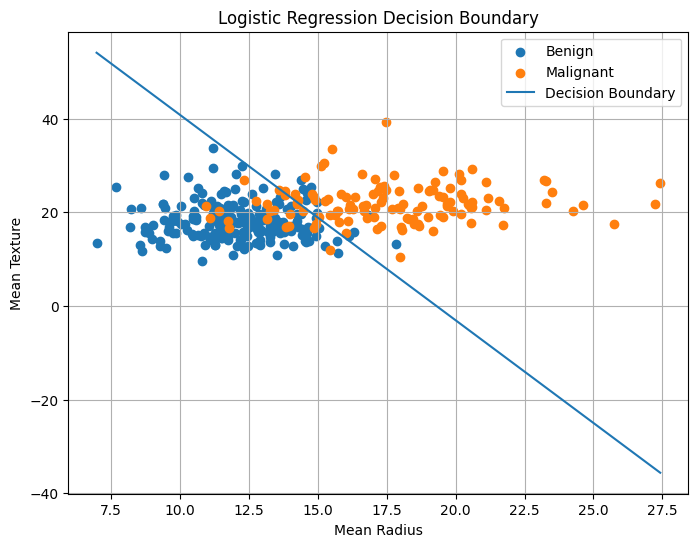

In [ ]:
x_values = np.linspace(
    X_train_raw[:, 0].min(),
    X_train_raw[:, 0].max(),
    100)

y_values = -(w_orig[0] + w_orig[1] * x_values) / w_orig[2]
plt.figure(figsize=(8, 6))
plt.scatter(
    X_train_raw[y_train == 0, 0],
    X_train_raw[y_train == 0, 1],
    label="Benign")

plt.scatter(
    X_train_raw[y_train == 1, 0],
    X_train_raw[y_train == 1, 1],
    label="Malignant")

plt.plot(x_values, y_values, label="Decision Boundary")
plt.xlabel("Mean Radius")
plt.ylabel("Mean Texture")
plt.title("Logistic Regression Decision Boundary")
plt.legend()
plt.grid()
plt.show()

## Decision Boundary in Original Coordinates

We plotted the decision boundary using the converted weights and the original, unstandardized training features: Mean Radius and Mean Texture.

The boundary represents the points where the model's predicted probability is 0.5, separating the two predicted classes.

# **Part D : Softmax Classifier:**

In [ ]:

# Retrieve the PROCESSED Digits dataset
X_train_final, X_val_final, X_test_final, y_train, y_val, y_test = processed_data["Digits"]

def softmax(S):
    S_shifted = S - np.max(S, axis=1, keepdims=True)
    exp_scores = np.exp(S_shifted)
    P = exp_scores / np.sum(exp_scores, axis=1, keepdims=True)
    return P

# 2. Stable cross-entropy loss + regularization
def softmax_loss(W, X, y, lam=0.0):
    N = X.shape[0]
    S = X @ W
    m = np.max(S, axis=1, keepdims=True)
    log_sum_exp = ( m[:, 0]+ np.log(np.sum(np.exp(S - m), axis=1))) #li=log sum e^s -true class score
    correct_scores = S[np.arange(N), y]
    data_loss = np.mean(log_sum_exp - correct_scores)
    reg_loss = (lam / 2) * np.sum(W[1:, :] ** 2)
    return data_loss + reg_loss

 # 3. Gradient
def softmax_grad(W, X, y, lam=0.0):
    N = X.shape[0]
    S = X @ W
    P = softmax(S)
    Y = np.eye(W.shape[1])[y]#one hot code
    grad = (X.T @ (P - Y)) / N
    grad[1:, :] += lam * W[1:, :]
    return grad
#4.check w=0
W_zero = np.zeros((65, 10))
loss_zero = softmax_loss(
    W_zero,
    X_train_final,
    y_train,
    lam=0.1
)
print("Loss at W=0:", loss_zero)
assert np.isclose(loss_zero, np.log(10))



Loss at W=0: 2.3025850929940463


In [ ]:
def predict_softmax(W, X):
    scores = X @ W
    probabilities = softmax(scores)
    return np.argmax(probabilities, axis=1)

def calculate_accuracy(W, X, y):
    predictions = predict_softmax(W, X)
    return np.mean(predictions == y)

def train_softmax(X_train, y_train, X_val, y_val,
                  eta, lam=0.0, epochs=100, batch_size=64):

    N = X_train.shape[0]
    K = 10  #10 possible classes
    W = np.zeros((X_train.shape[1], K))
    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": [] }
        #Creates a random permutation of the image indices.
    rng = np.random.default_rng(42)
    for epoch in range(epochs):
        indices = rng.permutation(N)
        X_shuffled = X_train[indices]
        y_shuffled = y_train[indices]

        # Divide into mini-batches
        for start in range(0, N, batch_size):
            end = start + batch_size
            X_batch = X_shuffled[start:end]
            y_batch = y_shuffled[start:end]

            # Calculate gradient
            grad = softmax_grad(W, X_batch, y_batch, lam)
            # Update weights
            W = W - eta * grad
        # Evaluate after each epoch
        history["train_loss"].append(
            softmax_loss(W, X_train, y_train, lam)
        )
        history["val_loss"].append(
            softmax_loss(W, X_val, y_val, lam)
        )
        history["train_acc"].append(
            calculate_accuracy(W, X_train, y_train)
        )
        history["val_acc"].append(
            calculate_accuracy(W, X_val, y_val)
        )

    return W, history
results = {}
learning_rates = [0.01, 0.1, 0.5, 1.0]
for n in learning_rates:
    W, history = train_softmax(
        X_train_final, y_train,
        X_val_final, y_val,
        eta=n,
        lam=0.0,
        epochs=100,
        batch_size=64 )
    results[n] = {
        "W": W,
        "history": history
    }
    print("Finished eta =", n)

Finished eta = 0.01
Finished eta = 0.1
Finished eta = 0.5
Finished eta = 1.0


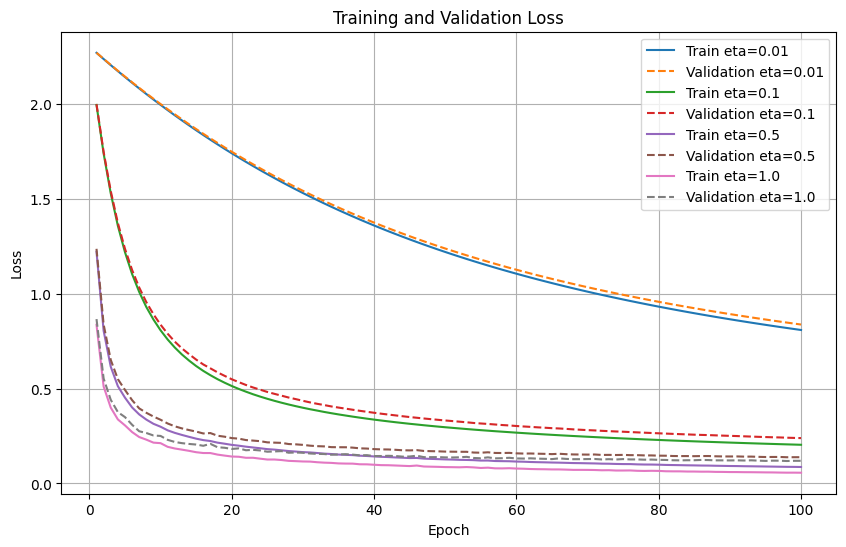

In [ ]:
#Plot the losses
import matplotlib.pyplot as plt

epochs = range(1, 101)

plt.figure(figsize=(10, 6))

for n in learning_rates:
    history = results[n]["history"]

    plt.plot(
        epochs,
        history["train_loss"],
        label=f"Train eta={n}"
    )

    plt.plot(
        epochs,
        history["val_loss"],
        linestyle="--",
        label=f"Validation eta={n}"
    )

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid()
plt.show()

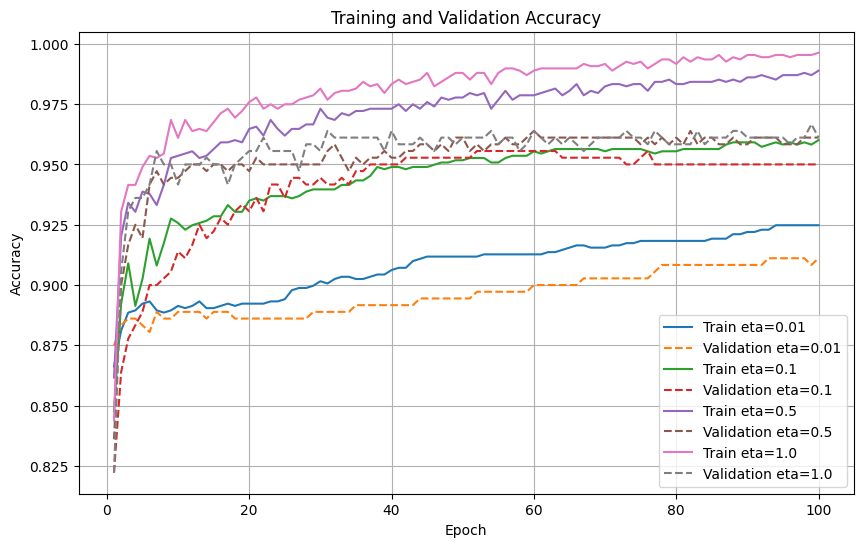

In [ ]:
#plot accurancy
plt.figure(figsize=(10, 6))

for n in learning_rates:
    history = results[n]["history"]

    plt.plot(
        epochs,
        history["train_acc"],
        label=f"Train eta={n}"
    )

    plt.plot(
        epochs,
        history["val_acc"],
        linestyle="--",
        label=f"Validation eta={n}"
    )

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid()
plt.show()

In [ ]:
#result table
import pandas as pd

rows = []

for n in learning_rates:
    history = results[n]["history"]

    rows.append({
        "Learning Rate": n,
        "Final Train Loss": history["train_loss"][-1],
        "Final Val Loss": history["val_loss"][-1],
        "Final Train Accuracy": history["train_acc"][-1],
        "Final Val Accuracy": history["val_acc"][-1]
    })

results_table = pd.DataFrame(rows)

print(results_table)
best_eta = results_table.loc[
    results_table["Final Val Loss"].idxmin(),
    "Learning Rate"
]

print("Best learning rate:", best_eta)

   Learning Rate  Final Train Loss  Final Val Loss  Final Train Accuracy  \
0           0.01          0.808641        0.837388              0.924791   
1           0.10          0.203817        0.238951              0.960074   
2           0.50          0.086785        0.138329              0.988858   
3           1.00          0.056569        0.119327              0.996286   

   Final Val Accuracy  
0            0.911111  
1            0.950000  
2            0.961111  
3            0.961111  
Best learning rate: 1.0


In [ ]:
lambdas = [0, 1e-4, 1e-3, 1e-2, 1e-1]
lambda_results = {}
for lam in lambdas:

    W, history = train_softmax(
        X_train_final, y_train,
        X_val_final, y_val,
        eta=best_eta,
        lam=lam,
        epochs=100,
        batch_size=64
    )
    lambda_results[lam] = {
        "W": W,
        "history": history
    }

    print("Finished lambda =", lam)
    rows = []

for lam in lambdas:
    history = lambda_results[lam]["history"]

    rows.append({
        "Lambda": lam,
        "Train Loss": history["train_loss"][-1],
        "Validation Loss": history["val_loss"][-1],
        "Train Accuracy": history["train_acc"][-1],
        "Validation Accuracy": history["val_acc"][-1]
    })

lambda_table = pd.DataFrame(rows)

print(lambda_table)
best_lambda = lambda_table.sort_values(
    by=["Validation Accuracy", "Lambda"],
    ascending=[False, False]
).iloc[0]["Lambda"]

print("Best lambda:", best_lambda)
best_W = lambda_results[best_lambda]["W"]
test_accuracy = calculate_accuracy(
    best_W,
    X_test_final,
    y_test
)
print("Test Accuracy:", test_accuracy)

Finished lambda = 0
Finished lambda = 0.0001
Finished lambda = 0.001
Finished lambda = 0.01
Finished lambda = 0.1
   Lambda  Train Loss  Validation Loss  Train Accuracy  Validation Accuracy
0  0.0000    0.056569         0.119327        0.996286             0.961111
1  0.0001    0.091589         0.150828        0.996286             0.963889
2  0.0010    0.257953         0.304194        0.980501             0.966667
3  0.0100    0.746276         0.785556        0.938719             0.927778
4  0.1000    1.775121         1.803547        0.641597             0.633333
Best lambda: 0.001
Test Accuracy: 0.9527777777777777


In [ ]:
#19.
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import numpy as np
import pandas as pd

N_train = X_train_final.shape[0]

# Remove bias column for sklearn.
# sklearn adds its own automatically.
X_train_sklearn = X_train_final[:, 1:]
X_val_sklearn = X_val_final[:, 1:]
X_test_sklearn = X_test_final[:, 1:]

sklearn_lambda_results = {}

for lam in lambdas:
    if lam == 0:
        C = np.inf
    else:
        C = 1 / (lam * N_train)

    model = LogisticRegression(C=C,max_iter=10000,
        solver="lbfgs")

    model.fit(X_train_sklearn, y_train)

    val_pred = model.predict(X_val_sklearn)
    test_pred = model.predict(X_test_sklearn)

    sklearn_lambda_results[lam] = {
        "model": model,
        "val_acc": accuracy_score(y_val, val_pred),
        "test_acc": accuracy_score(y_test, test_pred),
        "test_pred": test_pred
    }

    print("Finished lambda =", lam, "C =", C)
    rows = []

for lam in lambdas:

    own_history = lambda_results[lam]["history"]

    rows.append({
        "Lambda": lam,

        "Own Val Accuracy":
            own_history["val_acc"][-1],#means the last element of the list.
#Because your training history stores validation accuracy after every epoch.

        "Sklearn Val Accuracy":
            sklearn_lambda_results[lam]["val_acc"],

        "Own Test Accuracy":
            accuracy_score(
                y_test,
                predict_softmax(
                    lambda_results[lam]["W"],
                    X_test_final
                )
            ),

        "Sklearn Test Accuracy":
            sklearn_lambda_results[lam]["test_acc"]
    })

comparison_table = pd.DataFrame(rows)

print(comparison_table)

Finished lambda = 0 C = inf
Finished lambda = 0.0001 C = 9.285051067780872
Finished lambda = 0.001 C = 0.9285051067780873
Finished lambda = 0.01 C = 0.09285051067780874
Finished lambda = 0.1 C = 0.009285051067780872
   Lambda  Own Val Accuracy  Sklearn Val Accuracy  Own Test Accuracy  \
0  0.0000          0.961111              0.955556           0.958333   
1  0.0001          0.963889              0.975000           0.958333   
2  0.0010          0.966667              0.972222           0.952778   
3  0.0100          0.927778              0.947222           0.925000   
4  0.1000          0.633333              0.902778           0.619444   

   Sklearn Test Accuracy  
0               0.955556  
1               0.961111  
2               0.955556  
3               0.933333  
4               0.886111  


In [ ]:
# direct c values
C_values = [0.1, 1, 10, 100]

C_results = {}

for C in C_values:

    model = LogisticRegression(
        C=C,
        max_iter=10000,
        solver="lbfgs"
    )

    model.fit(X_train_sklearn, y_train)

    val_pred = model.predict(X_val_sklearn)
    test_pred = model.predict(X_test_sklearn)

    C_results[C] = {
        "model": model,
        "val_acc": accuracy_score(y_val, val_pred),
        "test_acc": accuracy_score(y_test, test_pred)
    }

C_table = pd.DataFrame([
    {
        "C": C,
        "Validation Accuracy": C_results[C]["val_acc"],
        "Test Accuracy": C_results[C]["test_acc"]
    }
    for C in C_values
])

print(C_table)
#Compare test predictions for lambda*
own_test_pred = predict_softmax(best_W, X_test_final)

sklearn_test_pred = sklearn_lambda_results[
    best_lambda
]["test_pred"]

agreement = np.mean(
    own_test_pred == sklearn_test_pred
)

print("Prediction agreement:", agreement)
print("Agreement percentage:", agreement * 100, "%")

assert agreement >= 0.97

       C  Validation Accuracy  Test Accuracy
0    0.1             0.950000       0.938889
1    1.0             0.972222       0.955556
2   10.0             0.963889       0.955556
3  100.0             0.961111       0.955556
Prediction agreement: 0.9916666666666667
Agreement percentage: 99.16666666666667 %


y_test shape: (360,)
y_pred shape: (360,)


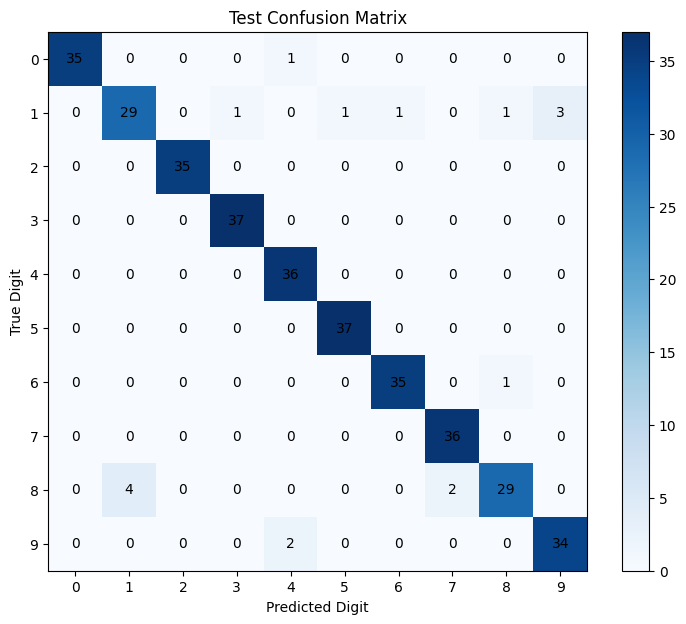

   precision    recall  f1-score  support
0   1.000000  0.972222  0.985915     36.0
1   0.878788  0.805556  0.840580     36.0
2   1.000000  1.000000  1.000000     35.0
3   0.973684  1.000000  0.986667     37.0
4   0.923077  1.000000  0.960000     36.0
5   0.973684  1.000000  0.986667     37.0
6   0.972222  0.972222  0.972222     36.0
7   0.947368  1.000000  0.972973     36.0
8   0.935484  0.828571  0.878788     35.0
9   0.918919  0.944444  0.931507     36.0
    True Digit  Predicted Digit  Number of Errors
73           8                1                 4
17           1                9                 3
79           8                7                 2


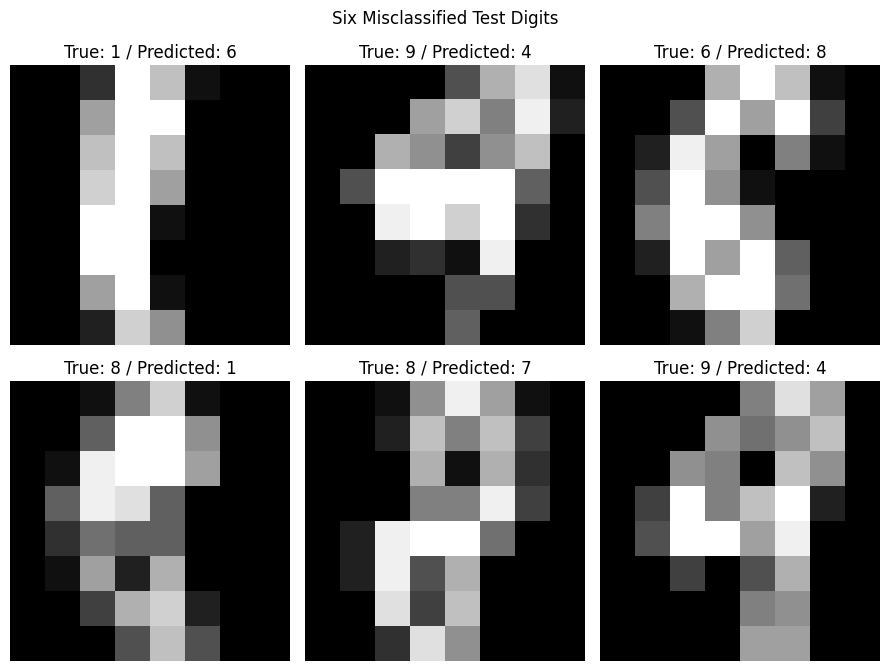

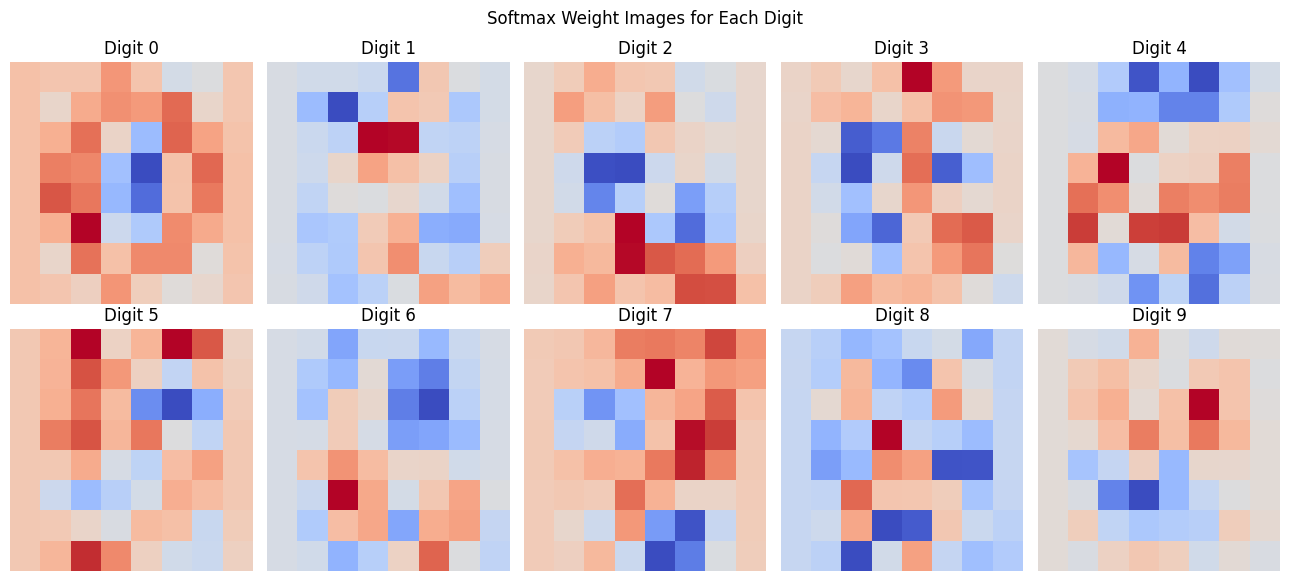

In [ ]:
#error analysis
# Generate predictions for the test set
scores = X_test_final @ best_W

probabilities = softmax(scores)

y_pred = np.argmax(probabilities, axis=1)

print("y_test shape:", y_test.shape)
print("y_pred shape:", y_pred.shape)
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(10)
)

plt.figure(figsize=(9, 7))

plt.imshow(cm, cmap="Blues")

plt.colorbar()

plt.xticks(range(10))
plt.yticks(range(10))

plt.xlabel("Predicted Digit")
plt.ylabel("True Digit")
plt.title("Test Confusion Matrix")

# Display the numbers inside the cells
for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j],
                 ha="center", va="center")

plt.show()
from sklearn.metrics import classification_report

report = classification_report(
    y_test,
    y_pred,
    labels=np.arange(10),
    output_dict=True,
    zero_division=0
)

metrics_table = pd.DataFrame(report).T

print(metrics_table.loc[
    [str(i) for i in range(10)],
    ["precision", "recall", "f1-score", "support"]
])
#Find the three most confused pairs
cm_no_diagonal = cm.copy()

np.fill_diagonal(cm_no_diagonal, 0)

pairs = []

for i in range(10):
    for j in range(10):

        if i != j:
            pairs.append({
                "True Digit": i,
                "Predicted Digit": j,
                "Number of Errors": cm_no_diagonal[i, j]
            })

pairs_table = pd.DataFrame(pairs)

top_three = pairs_table.sort_values(
    by="Number of Errors",
    ascending=False
).head(3)

print(top_three)
#Display six misclassified digits
# Find incorrect predictions
wrong_indices = np.where(y_test != y_pred)[0]

# Select six examples
selected_indices = wrong_indices[:6]

fig, axes = plt.subplots(2, 3, figsize=(9, 7))

for ax, idx in zip(axes.flat, selected_indices):

    # Remove bias column and reshape
    image = X_test_final[idx, 1:].reshape(8, 8)

    ax.imshow(image, cmap="gray")

    ax.set_title(
        f"True: {y_test[idx]} / Predicted: {y_pred[idx]}"
    )

    ax.axis("off")

plt.suptitle("Six Misclassified Test Digits")
plt.tight_layout()
plt.show()
#Visualize the ten class weight images
# Remove bias row
class_weights = best_W[1:, :]

fig, axes = plt.subplots(2, 5, figsize=(13, 6))

for digit, ax in enumerate(axes.flat):

    weight_image = class_weights[:, digit].reshape(8, 8)

    im = ax.imshow(weight_image, cmap="coolwarm")

    ax.set_title(f"Digit {digit}")
    ax.axis("off")

plt.suptitle("Softmax Weight Images for Each Digit")

plt.tight_layout()
plt.show()

Digit 1 is the hardest because it has the lowest F1-score (0.841).
Digit 8 is the second hardest (0.879).
Digit 9 is the third hardest (0.932).

The model sometimes recognizes an 8 as a 1.
It sometimes recognizes a 1 as a 9.
It sometimes recognizes an 8 as a 7.

A linear model on raw pixels uses a weighted sum of individual pixel values and cannot effectively capture complex shapes, curves, rotations, or spatial relationships between pixels.

In [ ]:
#Softmax with K = 2 is Logistic Regression
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np

# Load breast cancer dataset
X_train_cancer, X_val_cancer, X_test_cancer, y_train_cancer, y_val_cancer, y_test_cancer = processed_data["Breast Cancer"]

# Two classes: 0 and 1
# 31 features including bias

np.random.seed(42)
W = np.random.randn(31, 2)
# 1. Calculate Softmax probabilities
scores = X_test_cancer @ W
P_softmax = softmax(scores)
# Probability of class 1
P_softmax_class1 = P_softmax[:, 1]

# 2. Calculate Sigmoid probabilities
w0 = W[:, 0]
w1 = W[:, 1]
w_difference = w1 - w0
z = X_test_cancer @ w_difference
P_sigmoid = 1 / (1 + np.exp(-z))

# 3. Compare the results
max_difference = np.max(
    np.abs(P_softmax_class1 - P_sigmoid)
)
print("Maximum difference:", max_difference)
assert np.allclose(
    P_softmax_class1,
    P_sigmoid,
    atol=1e-12
)
print("Softmax and Sigmoid are equivalent!")

Maximum difference: 7.216449660063518e-16
Softmax and Sigmoid are equivalent!


In [ ]:
#two Iris features: petal length and petal width.
X_train_iris, X_val_iris, X_test_iris, y_train_iris, y_val_iris, y_test_iris = splits["Iris"]

# prepare the data
X_train_iris = X_train_iris[:, 2:4]
X_val_iris = X_val_iris[:, 2:4]
X_test_iris = X_test_iris[:, 2:4]
print(X_train_iris.shape)
iris_scaler = Standardizer()
iris_scaler.fit(X_train_iris)
X_train_iris = iris_scaler.transform(X_train_iris)
X_val_iris = iris_scaler.transform(X_val_iris)
X_test_iris = iris_scaler.transform(X_test_iris)
X_train_iris_bias = add_bias(X_train_iris)
X_val_iris_bias = add_bias(X_val_iris)
X_test_iris_bias = add_bias(X_test_iris)
print("Training:", X_train_iris_bias.shape)
print("Validation:", X_val_iris_bias.shape)
print("Testing:", X_test_iris_bias.shape)


(90, 2)
Training: (90, 3)
Validation: (30, 3)
Testing: (30, 3)


(3, 3)
(3, 3)


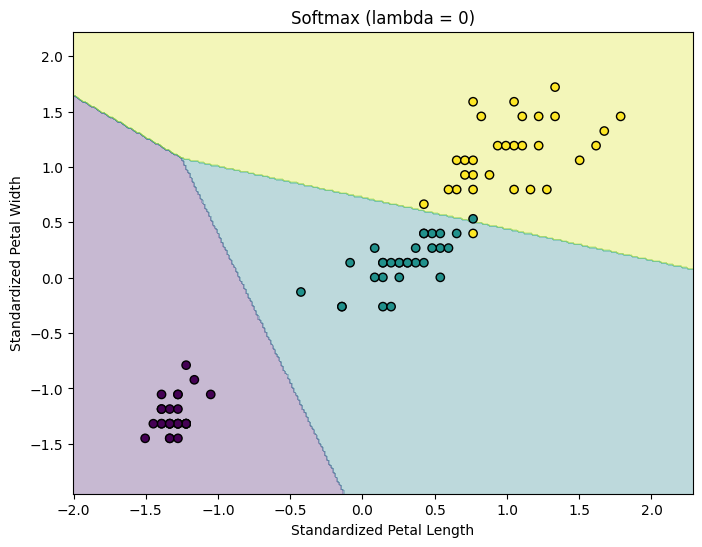

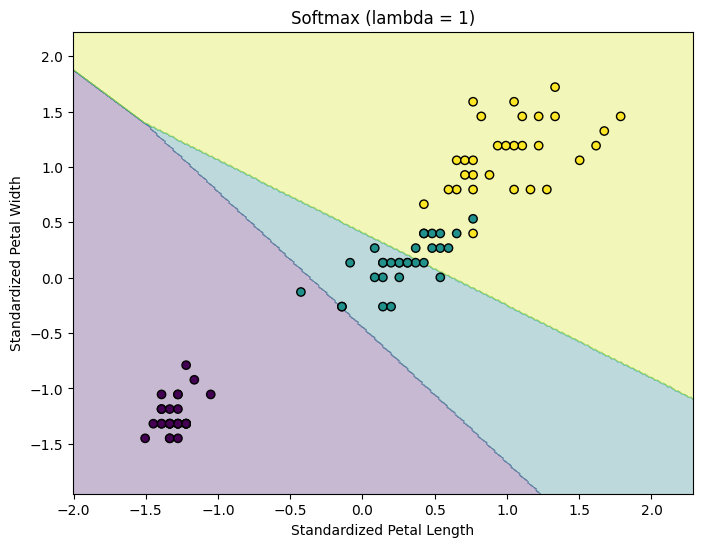

In [ ]:
#Train our Softmax classifier
def train_softmax_full_batch(X, y, eta=0.5, lam=0.0, epochs=2000):
    N = X.shape[0]
    K = len(np.unique(y))
    W = np.zeros((X.shape[1], K))
    for epoch in range(epochs):
        grad = softmax_grad(W, X, y, lam)
        W = W - eta * grad

    return W
# Train lambda = 0
W_iris_0 = train_softmax_full_batch(
    X_train_iris_bias,
    y_train_iris,
    eta=0.5,
    lam=0,
    epochs=2000
)
# Train lambda = 1
W_iris_1 = train_softmax_full_batch(
    X_train_iris_bias,
    y_train_iris,
    eta=0.5,
    lam=1,
    epochs=2000
)
print(W_iris_0.shape)
print(W_iris_1.shape)


################################################################################################plot
import matplotlib.pyplot as plt

def plot_decision_regions(X, y, W, title):

    # Create mesh grid
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    # Combine grid points
    grid = np.c_[xx.ravel(), yy.ravel()]

    # Add bias
    grid_bias = add_bias(grid)

    # Predict classes
    scores = grid_bias @ W
    probabilities = softmax(scores)
    Z = np.argmax(probabilities, axis=1)

    Z = Z.reshape(xx.shape)

    # Plot
    plt.figure(figsize=(8, 6))

    plt.contourf(xx, yy, Z, alpha=0.3, cmap="viridis")

    plt.scatter(
        X[:, 0], X[:, 1],
        c=y,
        edgecolors="black",
        cmap="viridis"
    )

    plt.xlabel("Standardized Petal Length")
    plt.ylabel("Standardized Petal Width")
    plt.title(title)
    plt.show()

    ###############call
plot_decision_regions(
   X_train_iris, y_train_iris, W_iris_0,
  "Softmax (lambda = 0)"
)

plot_decision_regions(
    X_train_iris, y_train_iris, W_iris_1,
    "Softmax (lambda = 1)"
)

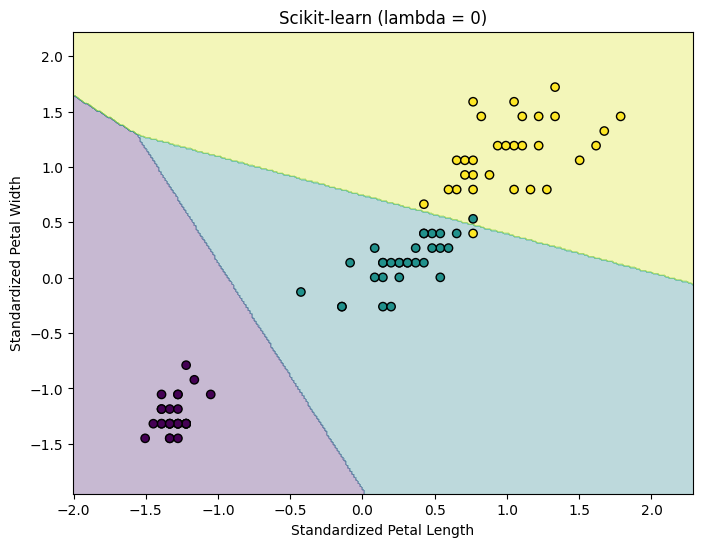

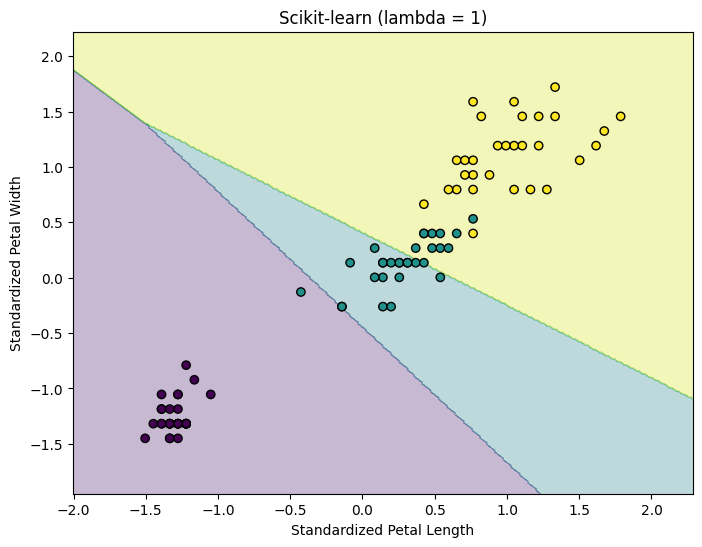

In [ ]:
#skitlearn
from sklearn.linear_model import LogisticRegression

model_0 = LogisticRegression(
    C=1e12,
    max_iter=10000,
    solver="lbfgs"
)

model_1 = LogisticRegression(
    C=1/90,
    max_iter=10000,
    solver="lbfgs"
)

model_0.fit(X_train_iris, y_train_iris)
model_1.fit(X_train_iris, y_train_iris)
####################################################################plot
def plot_sklearn_regions(X, y, model, title):

    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]

    Z = model.predict(grid)
    Z = Z.reshape(xx.shape)

    plt.figure(figsize=(8, 6))

    plt.contourf(xx, yy, Z, alpha=0.3, cmap="viridis")

    plt.scatter(
        X[:, 0], X[:, 1],
        c=y,
        edgecolors="black",
        cmap="viridis"
    )

    plt.xlabel("Standardized Petal Length")
    plt.ylabel("Standardized Petal Width")
    plt.title(title)
    plt.show()
# Call the function
plot_sklearn_regions(
    X_train_iris, y_train_iris, model_0,
    "Scikit-learn (lambda = 0)"
)

plot_sklearn_regions(
    X_train_iris, y_train_iris, model_1,
    "Scikit-learn (lambda = 1)"
)

# **Part E: SVM:**

# Part E — Support Vector Machines
## Task 23 — Linear SVM from scratch (Breast Cancer, standardized, labels ±1, λ = 0.01)


### Model and subgradient
$f(x)=w\cdot x+b,\; y_i\in\{-1,+1\}$,

$$J(w,b)=\frac{\lambda}{2}\|w\|^2+\frac1N\sum_i \max(0,\,1-y_i f(x_i))$$

The hinge is not differentiable at $y_if(x_i)=1$, so we use a subgradient. With $V=\{i:\;y_if(x_i)<1\}$:

$$\frac{\partial J}{\partial w}=\lambda w-\frac1N\sum_{i\in V}y_ix_i,\qquad \frac{\partial J}{\partial b}=-\frac1N\sum_{i\in V}y_i$$

The bias $b$ is **not** regularized. Only samples that touch or violate the margin contribute to the gradient.

In [ ]:
import warnings
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import SVC, LinearSVC   # for later comparison
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)

# Breast Cancer from the shared pipeline. The first column is the bias column of ones;
# the SVM keeps b separate, so it is dropped here. Labels are converted to -1 / +1.
Xc_tr, Xc_va, Xc_te, yc_tr, yc_va, yc_te = processed_data["Breast Cancer"]
Xc_tr, Xc_va, Xc_te = Xc_tr[:, 1:], Xc_va[:, 1:], Xc_te[:, 1:]
yc_tr, yc_va, yc_te = 2 * yc_tr - 1, 2 * yc_va - 1, 2 * yc_te - 1
n_train = len(yc_tr)


def svm_objective(w, b, X, y, lam):
    hinge = np.maximum(0, 1 - y * (X @ w + b))
    return 0.5 * lam * (w @ w) + hinge.mean()


def svm_subgradient(w, b, X, y, lam):
    violating = y * (X @ w + b) < 1
    grad_w = lam * w - X[violating].T @ y[violating] / len(y)
    grad_b = -y[violating].sum() / len(y)
    return grad_w, grad_b


def svm_predict(w, b, X):
    return np.where(X @ w + b >= 0, 1, -1)


def train_svm(X, y, X_val, y_val, lam, n_iter, step):
    # full-batch subgradient descent from w = 0, b = 0
    w, b = np.zeros(X.shape[1]), 0.0
    objectives, val_accuracies = [], []
    for t in range(1, n_iter + 1):
        grad_w, grad_b = svm_subgradient(w, b, X, y, lam)
        eta = step(t)
        w, b = w - eta * grad_w, b - eta * grad_b
        objectives.append(svm_objective(w, b, X, y, lam))
        val_accuracies.append(accuracy(y_val, svm_predict(w, b, X_val)))
    return w, b, np.array(objectives), np.array(val_accuracies)


# Gradient check (Part A grad_check) with theta = [w, b], eps = 1e-6
lam = 0.01
f = lambda theta: svm_objective(theta[:-1], theta[-1], Xc_tr, yc_tr, lam)
g = lambda theta: np.append(*svm_subgradient(theta[:-1], theta[-1], Xc_tr, yc_tr, lam))

rng = np.random.default_rng(42)
theta0 = rng.normal(0, 0.1, Xc_tr.shape[1] + 1)
error = grad_check(f, g, theta0, eps=1e-6)
print(f"Relative error: {error:.2e}  ->", "passed" if error < 1e-5 else "FAILED")

Relative error: 1.59e-10  -> passed


### Results

In [ ]:
schedules = {
    "constant η = 0.1": lambda t: 0.1,
    "constant η = 1.0": lambda t: 1.0,
    "η_t = 1/√t":       lambda t: 1 / np.sqrt(t),
}
runs = {name: train_svm(Xc_tr, yc_tr, Xc_va, yc_va, lam, 3000, step) for name, step in schedules.items()}

summary = pd.DataFrame({
    name: {"final J": objs[-1], "std of J (last 200 it.)": objs[-200:].std(), "final val acc": accs[-1]}
    for name, (w, b, objs, accs) in runs.items()
}).T
display(summary)

,final J,std of J (last 200 it.),final val acc
constant η = 0.1,0.060544,0.000043,0.973684
constant η = 1.0,0.060961,0.000448,0.973684
η_t = 1/√t,0.060798,0.000011,0.973684


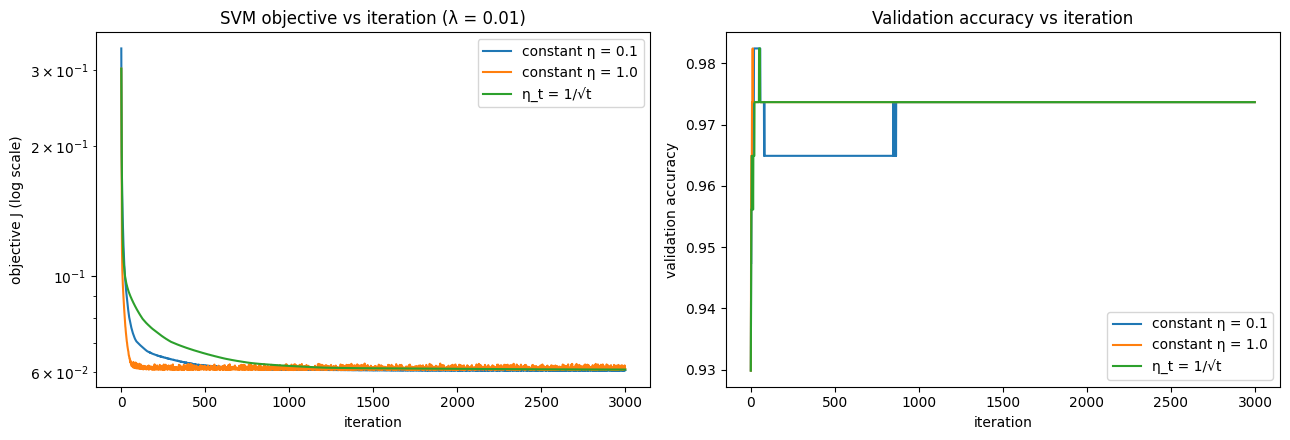

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, (w, b, objs, accs) in runs.items():
    axes[0].plot(objs, label=name)
    axes[1].plot(accs, label=name)

axes[0].set_yscale("log")
axes[0].set(title="SVM objective vs iteration (λ = 0.01)", xlabel="iteration", ylabel="objective J (log scale)")
axes[1].set(title="Validation accuracy vs iteration", xlabel="iteration", ylabel="validation accuracy")
axes[0].legend(); axes[1].legend()
plt.tight_layout(); plt.show()

## Task 24 — Comparison with scikit-learn

**Task.** Run 20,000 iterations with η_t = 1/√t and compare with `SVC(kernel="linear", C=1/(λ·N_train))`. Then sweep λ and compare with `SVC` and `LinearSVC(loss="hinge")`.

In [ ]:
lambdas = [1e-4, 1e-3, 1e-2, 1e-1, 1]
fits = {}

for lam_i in lambdas:
    C = 1 / (lam_i * n_train)
    w, b, _, _ = train_svm(Xc_tr, yc_tr, Xc_va, yc_va, lam_i, 20000, lambda t: 1 / np.sqrt(t))
    fits[lam_i] = {
        "mine": (w, b),
        "SVC": SVC(kernel="linear", C=C).fit(Xc_tr, yc_tr),
        "LinearSVC": LinearSVC(loss="hinge", C=C, dual=True, tol=1e-8, max_iter=1_000_000, random_state=42).fit(Xc_tr, yc_tr),
    }

### Results (λ = 0.01)

In [ ]:
w, b = fits[0.01]["mine"]
svc = fits[0.01]["SVC"]
w_sk, b_sk = svc.coef_.ravel(), svc.intercept_[0]

j_mine = svm_objective(w, b, Xc_tr, yc_tr, 0.01)
j_sk = svm_objective(w_sk, b_sk, Xc_tr, yc_tr, 0.01)
cosine = w @ w_sk / (np.linalg.norm(w) * np.linalg.norm(w_sk))
agreement = np.mean(svm_predict(w, b, Xc_te) == svc.predict(Xc_te))
n_sv_mine = int((yc_tr * (Xc_tr @ w + b) <= 1).sum())
n_sv_sk = int(svc.n_support_.sum())

display(pd.DataFrame([
    ["Objective J (relative gap)", f"{j_mine:.5f} vs {j_sk:.5f} ({abs(j_mine - j_sk) / j_sk:.1e})", abs(j_mine - j_sk) / j_sk < 1e-3],
    ["Cosine similarity of w", f"{cosine:.5f}", cosine >= 0.99],
    ["Test-prediction agreement", f"{agreement:.4f}", agreement >= 0.98],
    ["Margin width 2/||w||", f"{2 / np.linalg.norm(w):.4f} vs {2 / np.linalg.norm(w_sk):.4f}", True],
    ["#points with y·f(x) ≤ 1 vs n_support_", f"{n_sv_mine} vs {n_sv_sk}", abs(n_sv_mine - n_sv_sk) <= 5],
], columns=["Quantity (mine vs SVC)", "Value", "Within tolerance"]).set_index("Quantity (mine vs SVC)"))

,Value,Within tolerance
Quantity (mine vs SVC),,
Objective J (relative gap),0.06045 vs 0.06044 (2.0e-04),True
Cosine similarity of w,0.99969,True
Test-prediction agreement,1.0000,True
Margin width 2/||w||,1.1318 vs 1.1291,True
#points with y·f(x) ≤ 1 vs n_support_,28 vs 32,True


### Results (λ sweep)

In [ ]:
def describe(model, w, b, lam, n_sv=None):
    # n_sv is given for SVC (n_support_); otherwise count the training points with y·f(x) <= 1
    if n_sv is None:
        n_sv = int((yc_tr * (Xc_tr @ w + b) <= 1).sum())
    return {"λ": lam, "C": f"{1 / (lam * n_train):.3g}", "model": model,
            "val acc": accuracy(yc_va, svm_predict(w, b, Xc_va)),
            "margin 2/||w||": 2 / np.linalg.norm(w), "#SV": n_sv,
            "objective J": svm_objective(w, b, Xc_tr, yc_tr, lam), "|b|": abs(b)}


rows = []
for lam_i, models in fits.items():
    w, b = models["mine"]
    rows.append(describe("mine", w, b, lam_i))
    svc = models["SVC"]
    rows.append(describe("SVC", svc.coef_.ravel(), svc.intercept_[0], lam_i, int(svc.n_support_.sum())))
    lsvc = models["LinearSVC"]
    rows.append(describe("LinearSVC", lsvc.coef_.ravel(), lsvc.intercept_[0], lam_i))

display(pd.DataFrame(rows).round(4).set_index(["λ", "C", "model"]))

val acc  margin 2/||w||  #SV  objective J     |b|
λ      C       model                                                       
0.0001 29.3    mine        0.9649          0.5923   15       0.0304  0.2756
               SVC         0.9474          0.1460   22       0.0094  1.3773
               LinearSVC   0.9474          0.1460   13       0.0094  1.3214
0.0010 2.93    mine        0.9737          0.6539   17       0.0358  0.2212
               SVC         0.9649          0.4620   28       0.0322  0.2319
               LinearSVC   0.9649          0.4634   22       0.0322  0.2030
0.0100 0.293   mine        0.9737          1.1318   28       0.0604  0.1359
               SVC         0.9737          1.1291   32       0.0604  0.1290
               LinearSVC   0.9737          1.1235   27       0.0604  0.1135
0.1000 0.0293  mine        0.9825          2.1688   56       0.1217  0.2273
               SVC         0.9825          2.1688   61       0.1217  0.2269
               LinearSVC   0.9737          2.1641   57       0.1222  0.1424
1.0000 0.00293 mine        0.9649          4.7117  122       0.2670  0.3270
               SVC         0.9649          4.7119  125       0.2670  0.3268
               LinearSVC   0.9649          4.4580  137       0.2813  0.1264

## Task 25 — Multiclass hinge loss vs. softmax (Digits)

**Task.** Use the scores $S=\tilde X W$ of Part D with the Weston–Watkins loss ($\Delta = 1$), verify the gradient, train with the Task 18 protocol and compare with softmax. Finish with a toy analysis of the two losses.

$$L(W)=\frac1N\sum_i\sum_{j\ne y_i}\max\bigl(0,\;S_{ij}-S_{iy_i}+\Delta\bigr)+\frac\lambda2\|W_{1:}\|^2$$

**Gradient.** For sample $i$, the term $j\neq y_i$ is active when $S_{ij}-S_{iy_i}+\Delta>0$. Let $B_{ij}=1$ for active terms, $B_{ij}=0$ for inactive ones, and $B_{iy_i}=-\sum_{j\ne y_i}B_{ij}$. Each active term increases the derivative with respect to $S_{ij}$ by 1 and decreases the one for the correct class by 1, so $\partial \ell_i/\partial S_{ij}=B_{ij}$. Since $S=\tilde X W$:

$$\frac{\partial L}{\partial W}=\frac1N\tilde X^\top B+\lambda\begin{bmatrix}0\\ W_{1:}\end{bmatrix}$$

**Loss at W = 0.** All scores are 0, so each of the $K-1$ terms equals $\Delta$ and $L(0)=\Delta(K-1)=9$.

### Implementation

In [ ]:
Xd_tr, Xd_va, Xd_te, yd_tr, yd_va, yd_te = processed_data["Digits"]   # pixels / 16 with a bias column
n_classes = 10


def hinge_loss_grad(W, X, y, lam, delta=1.0):
    n = len(y)
    scores = X @ W
    margins = np.maximum(0, scores - scores[np.arange(n), y][:, None] + delta)
    margins[np.arange(n), y] = 0                       # j = y_i is not part of the sum
    loss = margins.sum() / n + 0.5 * lam * np.sum(W[1:] ** 2)

    B = (margins > 0).astype(float)
    B[np.arange(n), y] = -B.sum(axis=1)
    grad = X.T @ B / n
    grad[1:] += lam * W[1:]                            # the bias row is not regularized
    return loss, grad


def train_hinge(eta, lam, epochs=100, batch_size=64):
    # mini-batch GD with the same shuffling as the softmax training in Part D
    W = np.zeros((Xd_tr.shape[1], n_classes))
    rng = np.random.default_rng(42)
    for _ in range(epochs):
        order = rng.permutation(len(yd_tr))
        for start in range(0, len(order), batch_size):
            batch = order[start:start + batch_size]
            W -= eta * hinge_loss_grad(W, Xd_tr[batch], yd_tr[batch], lam)[1]
    return W


def fit_hinge(eta, lam):
    W = train_hinge(eta, lam)
    return W, hinge_loss_grad(W, Xd_va, yd_va, lam)[0], accuracy(yd_va, np.argmax(Xd_va @ W, axis=1))


def fit_softmax(eta, lam):
    # reuses train_softmax from Part D
    W, history = train_softmax(Xd_tr, yd_tr, Xd_va, yd_va, eta=eta, lam=lam, epochs=100, batch_size=64)
    return W, history["val_loss"][-1], history["val_acc"][-1]


def tune(fit, etas, lams):
    # Task 18 protocol: (a) eta by validation loss at lambda = 0, (b) lambda by validation accuracy (ties -> larger lambda)
    eta_runs = {eta: fit(eta, 0.0) for eta in etas}
    eta_table = pd.DataFrame([{"η": e, "val loss": r[1], "val acc": r[2]} for e, r in eta_runs.items()])
    best_eta = eta_table.loc[eta_table["val loss"].idxmin(), "η"]

    lam_runs = {lam: eta_runs[best_eta] if lam == 0 else fit(best_eta, lam) for lam in lams}
    lam_table = pd.DataFrame([{"λ": l, "val acc": r[2]} for l, r in lam_runs.items()])
    best_acc = lam_table["val acc"].max()
    best_lam = max(lam_table.loc[np.isclose(lam_table["val acc"], best_acc), "λ"])
    return eta_table, lam_table, best_eta, best_lam, lam_runs[best_lam][0]


# Verification: loss at W = 0 and gradient check on 100 random entries
print("Loss at W = 0:", hinge_loss_grad(np.zeros((65, n_classes)), Xd_tr, yd_tr, 0.1)[0], "(expected 9)")

rng = np.random.default_rng(42)
W_random = rng.normal(0, 0.1, (65, n_classes))
error = grad_check(lambda W: hinge_loss_grad(W, Xd_tr, yd_tr, 0.1)[0],
                   lambda W: hinge_loss_grad(W, Xd_tr, yd_tr, 0.1)[1],
                   W_random, eps=1e-6, num_checks=100)
print(f"Gradient check (100 random entries): relative error = {error:.2e} ->", "passed" if error < 1e-5 else "FAILED")

Loss at W = 0: 9.0 (expected 9)
Gradient check (100 random entries): relative error = 4.08e-09 -> passed


### Results

In [ ]:
hinge_eta, hinge_lam, hinge_eta_best, hinge_lam_best, W_hinge = tune(fit_hinge, [0.01, 0.1, 0.5], [0, 1e-4, 1e-3, 1e-2])
soft_eta, soft_lam, soft_eta_best, soft_lam_best, W_soft = tune(fit_softmax, [0.01, 0.1, 0.5, 1.0], [0, 1e-4, 1e-3, 1e-2, 1e-1])

for title, table in [("Multiclass hinge: step size (λ = 0)", hinge_eta), (f"Multiclass hinge: λ (η* = {hinge_eta_best})", hinge_lam),
                     ("Softmax: step size (λ = 0)", soft_eta), (f"Softmax: λ (η* = {soft_eta_best})", soft_lam)]:
    print(title)
    display(table.round(4).set_index(table.columns[0]))

# test accuracy is reported once, for the selected models only
final = pd.DataFrame({
    "model": ["multiclass hinge", "softmax"],
    "η*": [hinge_eta_best, soft_eta_best],
    "λ*": [hinge_lam_best, soft_lam_best],
    "validation acc": [accuracy(yd_va, np.argmax(Xd_va @ W, axis=1)) for W in (W_hinge, W_soft)],
    "test acc": [accuracy(yd_te, np.argmax(Xd_te @ W, axis=1)) for W in (W_hinge, W_soft)],
})
display(final.round(4).set_index("model"))

Multiclass hinge: step size (λ = 0)


,val loss,val acc
η,,
0.01,0.3126,0.9500
0.10,0.1702,0.9611
0.50,0.1406,0.9611


Multiclass hinge: λ (η* = 0.5)


,val acc
λ,
0.0000,0.9611
0.0001,0.9639
0.0010,0.9694
0.0100,0.9444


Softmax: step size (λ = 0)


,val loss,val acc
η,,
0.01,0.8374,0.9111
0.10,0.2390,0.9500
0.50,0.1383,0.9611
1.00,0.1193,0.9611


Softmax: λ (η* = 1.0)


,val acc
λ,
0.0000,0.9611
0.0001,0.9639
0.0010,0.9667
0.0100,0.9278
0.1000,0.6333


,η*,λ*,validation acc,test acc
model,,,,
multiclass hinge,0.5,0.001,0.9694,0.9500
softmax,1.0,0.001,0.9667,0.9528


**Toy analysis.** Scores for a sample of true class 0.

In [ ]:
def svm_loss(scores, delta=1.0):
    return np.maximum(0, scores[1:] - scores[0] + delta).sum()


def cross_entropy(scores):
    m = scores.max()
    return m + np.log(np.exp(scores - m).sum()) - scores[0]      # stable log-sum-exp


toy = {"(a) [10, -5, -5]": [10, -5, -5], "(b) [100, -50, -50]": [100, -50, -50], "(c) [3.2, 5.1, -1.7]": [3.2, 5.1, -1.7]}
toy_table = pd.DataFrame({
    "multiclass SVM loss": {k: svm_loss(np.array(v, dtype=float)) for k, v in toy.items()},
    "softmax cross-entropy": {k: cross_entropy(np.array(v, dtype=float)) for k, v in toy.items()},
})
display(toy_table.apply(lambda col: col.map("{:.3g}".format)))

,multiclass SVM loss,softmax cross-entropy
"(a) [10, -5, -5]",0,6.12e-07
"(b) [100, -50, -50]",0,0
"(c) [3.2, 5.1, -1.7]",2.9,2.04


## Task 26 — Kernels and C (off-the-shelf)

**Task.** On Breast Cancer, compare linear, polynomial (degree 3, coef0 = 1) and RBF kernels at C = 1, then sweep C for the linear SVC.

### Results

In [ ]:
kernels = {
    "linear": SVC(kernel="linear", C=1),
    "polynomial (degree 3)": SVC(kernel="poly", degree=3, coef0=1, gamma="scale", C=1),
    "RBF": SVC(kernel="rbf", gamma="scale", C=1),
}
rows = []
for name, clf in kernels.items():
    clf.fit(Xc_tr, yc_tr)
    rows.append({"kernel": name, "train acc": clf.score(Xc_tr, yc_tr), "val acc": clf.score(Xc_va, yc_va),
                 "test acc": clf.score(Xc_te, yc_te), "#SV": int(clf.n_support_.sum())})
display(pd.DataFrame(rows).round(4).set_index("kernel"))

rows = []
for C in [0.001, 0.01, 0.1, 1, 10, 100]:
    clf = SVC(kernel="linear", C=C).fit(Xc_tr, yc_tr)
    rows.append({"C": C, "λ = 1/(C·N)": f"{1 / (C * n_train):.2e}", "train acc": clf.score(Xc_tr, yc_tr),
                 "val acc": clf.score(Xc_va, yc_va), "#SV": int(clf.n_support_.sum()),
                 "margin 2/||w||": 2 / np.linalg.norm(clf.coef_)})
display(pd.DataFrame(rows).round(4).set_index("C"))

,train acc,val acc,test acc,#SV
kernel,,,,
linear,0.9883,0.9649,0.9298,30
polynomial (degree 3),0.9912,0.9825,0.9737,52
RBF,0.9824,0.9825,0.9737,88


,λ = 1/(C·N),train acc,val acc,#SV,margin 2/||w||
C,,,,,
0.001,2.93e+00,0.9326,0.9561,175,6.7619
0.010,2.93e-01,0.9736,0.9737,83,3.1690
0.100,2.93e-02,0.9795,0.9649,43,1.5669
1.000,2.93e-03,0.9883,0.9649,30,0.6727
10.000,2.93e-04,0.9971,0.9386,23,0.2471
100.000,2.93e-05,1.0000,0.9474,22,0.1460


## Task 27 — Effect of γ (off-the-shelf)

**Task.** Fit an RBF SVC (C = 1) on the standardized features `mean radius` and `mean texture` for γ ∈ {0.01, 0.1, 1, 10, 100} and plot the decision regions for three values of γ with the support vectors circled.

### Results

,train acc,val acc,#SV
γ,,,
0.01,0.8827,0.8684,166
0.10,0.9003,0.8947,109
1.00,0.9120,0.8947,108
10.00,0.9296,0.8772,201
100.00,0.9824,0.7368,311


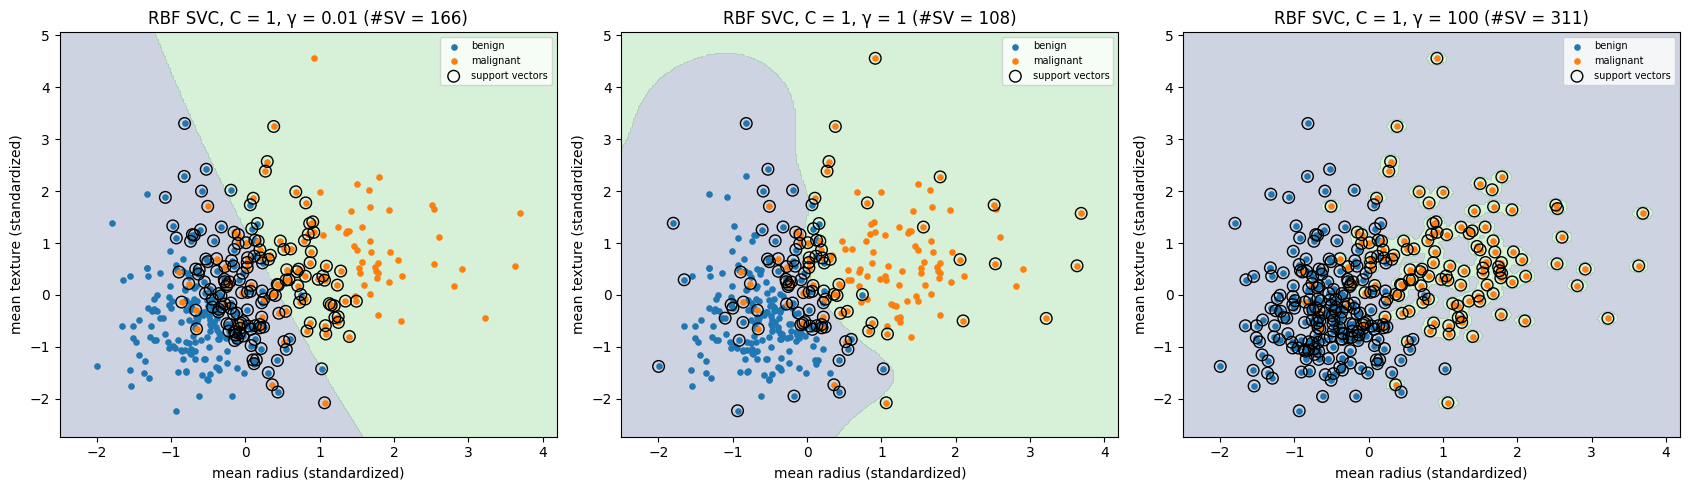

In [ ]:
X2_tr, X2_va = Xc_tr[:, :2], Xc_va[:, :2]        # mean radius, mean texture (already standardized)
gammas = [0.01, 0.1, 1, 10, 100]
rbf_models = {gamma: SVC(kernel="rbf", C=1, gamma=gamma).fit(X2_tr, yc_tr) for gamma in gammas}

display(pd.DataFrame([
    {"γ": gamma, "train acc": clf.score(X2_tr, yc_tr), "val acc": clf.score(X2_va, yc_va), "#SV": int(clf.n_support_.sum())}
    for gamma, clf in rbf_models.items()
]).round(4).set_index("γ"))


def plot_decision_regions_svm(clf, X, y, ax):
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 300),
                         np.linspace(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5, 300))
    zz = clf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, zz, alpha=0.25, levels=[-2, 0, 2])
    ax.scatter(*X[y == -1].T, s=14, label="benign")
    ax.scatter(*X[y == 1].T, s=14, label="malignant")
    ax.scatter(*clf.support_vectors_.T, s=70, facecolors="none", edgecolors="k", label="support vectors")
    ax.set(xlabel="mean radius (standardized)", ylabel="mean texture (standardized)")
    ax.legend(fontsize=7)


fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, gamma in zip(axes, [0.01, 1, 100]):
    plot_decision_regions_svm(rbf_models[gamma], X2_tr, yc_tr, ax)
    ax.set_title(f"RBF SVC, C = 1, γ = {gamma} (#SV = {rbf_models[gamma].n_support_.sum()})")
plt.tight_layout(); plt.show()

## Task 28 — Tuning on Digits (off-the-shelf)

**Task.** Run `GridSearchCV` for an RBF SVC on the Digits pixels (/ 16) over C ∈ {0.1, 1, 10, 100} and γ ∈ {1e-4, 1e-3, 1e-2, 1e-1, 1}, with 5-fold stratified CV on the training rows (cross-validation replaces the validation set). The test set is used once at the end.

### Results

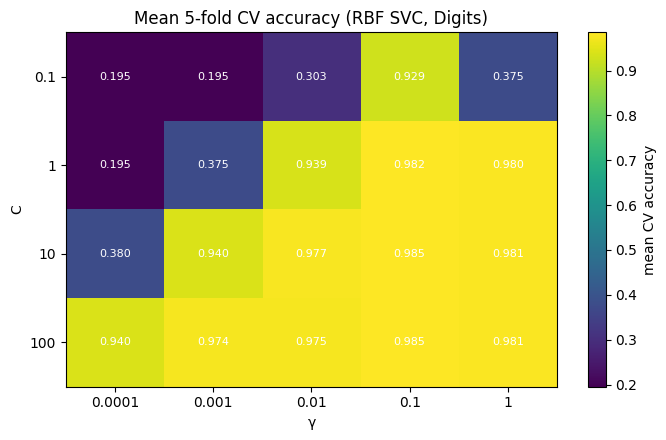

Best parameters: {'C': 10, 'gamma': 0.1}
Best mean CV accuracy: 0.9851
Test accuracy (reported once): 0.9917


In [ ]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

X_digits_tr, X_digits_te = Xd_tr[:, 1:], Xd_te[:, 1:]          # pixels / 16 without the bias column
param_grid = {"C": [0.1, 1, 10, 100], "gamma": [1e-4, 1e-3, 1e-2, 1e-1, 1]}
search = GridSearchCV(SVC(kernel="rbf"), param_grid, cv=StratifiedKFold(5, shuffle=True, random_state=42))
search.fit(X_digits_tr, yd_tr)

cv_scores = search.cv_results_["mean_test_score"].reshape(len(param_grid["C"]), len(param_grid["gamma"]))
fig, ax = plt.subplots(figsize=(7, 4.5))
image = ax.imshow(cv_scores, cmap="viridis", aspect="auto")
ax.set_xticks(range(len(param_grid["gamma"])), param_grid["gamma"])
ax.set_yticks(range(len(param_grid["C"])), param_grid["C"])
ax.set(xlabel="γ", ylabel="C", title="Mean 5-fold CV accuracy (RBF SVC, Digits)")
for i, j in np.ndindex(cv_scores.shape):
    ax.text(j, i, f"{cv_scores[i, j]:.3f}", ha="center", va="center", color="w", fontsize=8)
plt.colorbar(image, label="mean CV accuracy")
plt.tight_layout(); plt.show()

print("Best parameters:", search.best_params_)
print(f"Best mean CV accuracy: {search.best_score_:.4f}")
print(f"Test accuracy (reported once): {search.best_estimator_.score(X_digits_te, yd_te):.4f}")

# **Part F: Comparison & Synthesis:**

\| Model                  | Per-sample loss                                  | Gradient                                      | Output meaning              |
|------------------------|--------------------------------------------------|-----------------------------------------------|------------------------------|
| Linear regression      | $\frac{1}{2}(s-y)^2$                             | $s-y$                                         | Continuous value             |
| Logistic regression    | $-[y\log(p)+(1-y)\log(1-p)]$                     | $p-y$                                         | Positive-class probability   |
| Softmax classifier     | $-\log(p_y)$                                     | $p-e_y$                                       | Class probabilities          |
| Binary SVM             | $\max(0,1-ys)$                                   | $-y$ if $ys<1$, otherwise $0$                 | Classification margin        |
| Multiclass SVM         | $\sum_{j\ne y}\max(0,1+s_j-s_y)$                | Depends on violated margins                   | Class scores                 |

The three models whose gradients have the form prediction minus target are linear regression, logistic regression, and softmax classification.

SVM is the exception because hinge loss focuses on the classification margin rather than the difference between a predicted probability and the target. When the margin is satisfied, the gradient becomes zero.

## 31. Conclusions

**(a) When would I choose each model?**

- **Ridge regression:** When predicting a continuous numerical value and I want to reduce overfitting using L2 regularization.
- **Logistic regression:** For binary classification when I need an estimated probability for the positive class.
- **Softmax classifier:** For multiclass classification when I need probabilities for all classes.
- **Linear SVM:** When the classes can be separated reasonably well by a linear boundary, especially in high-dimensional data.
- **Kernel SVM:** When the relationship between classes is nonlinear and a linear decision boundary is insufficient.

**(b) Probabilities versus margins**

Logistic regression and softmax produce probabilities using sigmoid and softmax functions. However, these probabilities are not necessarily perfectly calibrated. Ridge regression produces numerical predictions, while SVM produces scores or margins rather than probabilities because its hinge loss focuses on satisfying classification margins.

**(c) How do the losses treat badly misclassified outliers?**

Squared loss increases quadratically as the prediction error increases, so it strongly penalizes large errors and is sensitive to outliers. Logistic loss and hinge loss increase approximately linearly for badly misclassified samples. Their gradients with respect to the score are bounded or constant while the sample is misclassified, making them less sensitive to large errors than squared loss.

**(d) Training and prediction costs**

For linear models, one full-batch training epoch generally costs \(O(Nd)\) for a single output, or \(O(NdK)\) for a K-class model. Prediction costs \(O(d)\) per sample, or \(O(dK)\) for K classes. Kernel SVM can require much more training time and memory because it works with an \(N\times N\) kernel matrix. Prediction also depends on the number of support vectors.

**(e) What surprised me most?**

I was surprised that a linear softmax classifier could classify most handwritten digits correctly, even though some digits have similar shapes. In my Digits results, digit 1 had the lowest F1-score (approximately 0.841), and digit 8 was sometimes confused with digit 1 or 7. This showed me that even a good model can struggle with visually similar classes. I also learned how regularization changes the decision boundaries in the Iris experiment.

# **Bonus:**

#2-Class Imbalance:

In [ ]:
X_train, X_val, X_test, y_train, y_val, y_test = processed_data["Breast Cancer"]
print(X_train.shape)
print(y_train.shape)

(341, 31)
(341,)


In [ ]:
rng = np.random.default_rng(0)
benign_indices = np.where(y_train == 0)[0]
malignant_indices = np.where(y_train == 1)[0]
n_malignant = int(0.15 * len(malignant_indices))

selected_malignant = rng.choice(
    malignant_indices,
    size=n_malignant,
    replace=False)

selected_indices = np.concatenate([
    benign_indices,
    selected_malignant])

rng.shuffle(selected_indices)

X_imbalanced = X_train[selected_indices]
y_imbalanced = y_train[selected_indices]

print("Original training size:",len(y_train))
print("Imbalanced training size:",len(y_imbalanced))
print("Benign samples:",np.sum(y_imbalanced == 0))
print("Malignant samples:",np.sum(y_imbalanced == 1))

Original training size: 341
Imbalanced training size: 233
Benign samples: 214
Malignant samples: 19


In [ ]:
w_unweighted = np.zeros(X_imbalanced.shape[1])
for epoch in range(3000):
    grad = gradient(X_imbalanced, y_imbalanced, w_unweighted, 0.01)
    w_unweighted = w_unweighted - 0.1 * grad
print("Unweighted Weights:", w_unweighted)

Unweighted Weights: [-1.95624126  0.41174065  0.64416975  0.41060718  0.39366442  0.26462933
  0.1201292   0.55239775  0.70780041  0.20629283 -0.24474953  0.26337483
 -0.03455885  0.16924533  0.27183641  0.15088196 -0.2883724  -0.04072135
  0.11036079  0.1495572  -0.41500667  0.48331359  0.70024028  0.44544513
  0.4505096   0.49178339  0.07133154  0.39241685  0.55028643  0.37010247
  0.00540077]


In [ ]:
N = len(y_imbalanced)
N_benign = np.sum(y_imbalanced == 0)
N_malignant = np.sum(y_imbalanced == 1)

w_benign = N / (2 * N_benign)
w_malignant = N / (2 * N_malignant)

print("Benign weight:", w_benign)
print("Malignant weight:", w_malignant)

Benign weight: 0.544392523364486
Malignant weight: 6.131578947368421


In [ ]:
def weighted_gradient(X,y,w,lambdaR,class_weights):
    p = sigmoid(X @ w)
    sample_weights = np.where(y == 0, class_weights[0], class_weights[1])
    grad = X.T @ (sample_weights * (p - y)) / len(y)
    grad[1:] += lambdaR * w[1:]
    return grad

In [ ]:
class_weights = [w_benign, w_malignant]
w_weighted = np.zeros(X_imbalanced.shape[1])
for epoch in range(3000):
    grad = weighted_gradient(
        X_imbalanced,
        y_imbalanced,
        w_weighted,
        0.01,
        class_weights)
    w_weighted = w_weighted - 0.1 * grad
print("Weighted Weights:", w_weighted)

Weighted Weights: [-0.69497685  0.49020848  0.82904265  0.49433843  0.4513642   0.3166299
  0.17795366  0.72389431  0.93648893  0.25534466 -0.2959229   0.25614894
 -0.08161393  0.14860727  0.28006366  0.22961268 -0.3793942  -0.05034653
  0.13341989  0.21278102 -0.560391    0.57974511  0.87401416  0.53376507
  0.52056595  0.57423141  0.04757052  0.48018436  0.6661444   0.44680844
 -0.0334577 ]


In [ ]:
from sklearn.metrics import precision_score, recall_score

test_scores_unweighted = sigmoid(X_test @ w_unweighted)
test_scores_weighted = sigmoid(X_test @ w_weighted)

test_pred_unweighted = (test_scores_unweighted >= 0.5).astype(int)
test_pred_weighted = (test_scores_weighted >= 0.5).astype(int)

precision_unweighted = precision_score(y_test, test_pred_unweighted)
recall_unweighted = recall_score(y_test, test_pred_unweighted)

precision_weighted = precision_score(y_test, test_pred_weighted)
recall_weighted = recall_score(y_test, test_pred_weighted)

comparison_table = pd.DataFrame({
    "Precision": [precision_unweighted, precision_weighted],
    "Recall": [recall_unweighted, recall_weighted]},
     index=["Unweighted", "Weighted"])
display(comparison_table)

,Precision,Recall
Unweighted,1.00000,0.833333
Weighted,0.97561,0.952381


In [ ]:
def precision_recall_curve_scratch(y_true, scores):
    sorted_indices = np.argsort(-scores)

    sorted_scores = scores[sorted_indices]
    sorted_y = y_true[sorted_indices]

    tp = np.cumsum(sorted_y)
    fp = np.cumsum(1 - sorted_y)

    distinct_indices = np.where(np.diff(sorted_scores) != 0)[0]
    distinct_indices = np.append(distinct_indices, len(sorted_scores) - 1)

    tp = tp[distinct_indices]
    fp = fp[distinct_indices]

    precision = tp / (tp + fp)
    recall = tp / np.sum(y_true)
    precision = np.concatenate([[1], precision])
    recall = np.concatenate([[0], recall])

    return precision, recall

In [ ]:
precision_unweighted_curve, recall_unweighted_curve = precision_recall_curve_scratch(
    y_test, test_scores_unweighted)
precision_weighted_curve, recall_weighted_curve = precision_recall_curve_scratch(
    y_test, test_scores_weighted)

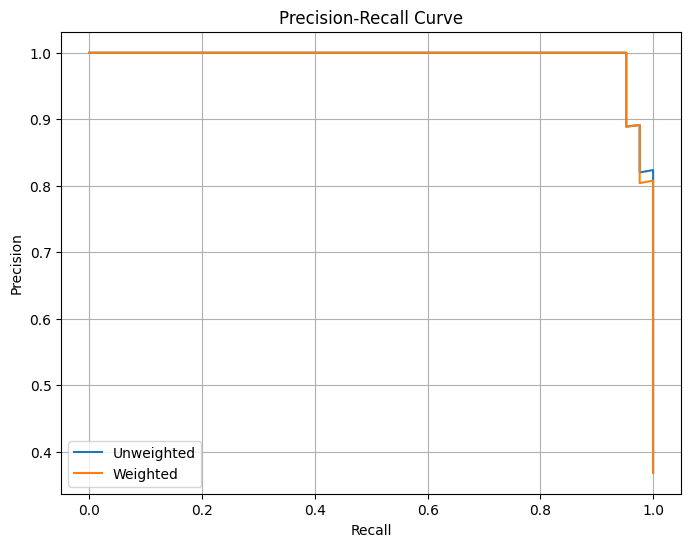

In [ ]:
plt.figure(figsize=(8, 6))
plt.plot(
    recall_unweighted_curve,
    precision_unweighted_curve,
    label="Unweighted")
plt.plot(
    recall_weighted_curve,
    precision_weighted_curve,
    label="Weighted")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.grid()
plt.show()

#Markdown:
Accuracy is misleading in imbalanced datasets because a model can achieve high accuracy by predicting only the majority class while failing to detect most minority-class samples. In this breast cancer problem, missing malignant cases (false negatives) is dangerous because it may delay diagnosis and treatment. Therefore, precision and recall provide more useful information about the model's performance, especially its ability to detect malignant cases.